#First version that led to the best result

##🥡 **Set form start**

In [1]:
MODEL_ARCHITECTURE = 'CNN_RNN' # 'CNN', 'RNN'
RNN_TYPE = 'LSTM' # 'LSTM', 'GRU', 'RNN'
RNN_BIDIRECTIONAL = True # For RNN only, or RNN part of CNN_RNN

BIDIRECTIONAL= True
ARCHITECTURE = 'LSTM'
# Training configuration
LEARNING_RATE = 1e-3
EPOCHS = 500
PATIENCE = 50
# Define the batch size
BATCH_SIZE =64

# General Architecture Parameters (for CNN/RNN if not combined)
HIDDEN_LAYERS = 2
HIDDEN_SIZE = 128

# Combined CNN-RNN specific parameters
CNN_RNN_CNN_LAYERS = 1
CNN_RNN_CNN_FILTERS = 128
CNN_RNN_CNN_KERNEL_SIZE = 7
CNN_RNN_CNN_POOL_SIZE = 1

CNN_RNN_RNN_LAYERS = 2
CNN_RNN_RNN_HIDDEN_SIZE = 128

# Regularisation
DROPOUT_RATE = 0.4          # Dropout probability
L1_LAMBDA = 0.0000   # L1 penalty
L2_LAMBDA = 0.0000   # L2 penalty
GAMMA = 2.5                 # For Focal Loss

# Define the window size
WINDOW_SIZE = 45
# Define the stride for overlapping windows
STRIDE = 5
# its how many data we "skip"
# Define the number of users for validation
N_VAL_USERS = 100

# Use pain_survey columns?
PAIN_SURVEY_COLUMNS = True

#giorni/ore/settimane/mesi?
TIME= 7.0

#seed
SEED = 42

## 📚 **Import Libraries**

In [2]:


# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np
import datetime


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
# from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.8.0+cu126
Device: cuda


## **Loading dataset**

In [3]:
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!pip install -q kaggle
!kaggle competitions download -c an2dl2526c1

!unzip an2dl2526c1.zip -d dataset



Saving kaggle.json to kaggle.json
  0% 0.00/82.0M [00:00<?, ?B/s]
100% 82.0M/82.0M [00:00<00:00, 1.71GB/s]
Archive:  an2dl2526c1.zip
  inflating: dataset/pirate_pain_test.csv  
  inflating: dataset/pirate_pain_train.csv  
  inflating: dataset/pirate_pain_train_labels.csv  
  inflating: dataset/sample_submission.csv  


later on, data are loaded and managed in next section, need to see for kaggle

## ❗**First look at data**


In [4]:

# Read the dataset into a DataFrame with specified column names
df = pd.read_csv('dataset/pirate_pain_train.csv', header=0)
dfTest=pd.read_csv('dataset/pirate_pain_test.csv', header=0)

# Remove rows with any missing values
# Even if here it's useless
df.dropna(axis=0, how='any', inplace=True)
dfTest.dropna(axis=0, how='any', inplace=True)

# Print the shape of the DataFrame
print(f"DataFrame shape: {df.shape}")

# Display the first 10 rows of the DataFrame
df.head(10)

DataFrame shape: (105760, 40)


,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,0,0,2,0,2,1,two,two,two,1.094705,...,3.499558e-06,1.945042e-06,3.999558e-06,1.153299e-05,0.000004,0.017592,0.013508,0.026798,0.027815,0.5
1,0,1,2,2,2,2,two,two,two,1.135183,...,3.976952e-07,6.765107e-07,6.019627e-06,4.643774e-08,0.000000,0.013352,0.000000,0.013377,0.013716,0.5
2,0,2,2,0,2,2,two,two,two,1.080745,...,1.533820e-07,1.698525e-07,1.446051e-06,2.424536e-06,0.000003,0.016225,0.008110,0.024097,0.023105,0.5
3,0,3,2,2,2,2,two,two,two,0.938017,...,1.006865e-05,5.511079e-07,1.847597e-06,5.432416e-08,0.000000,0.011832,0.007450,0.028613,0.024648,0.5
4,0,4,2,2,2,2,two,two,two,1.090185,...,4.437266e-06,1.735459e-07,1.552722e-06,5.825366e-08,0.000007,0.005360,0.002532,0.033026,0.025328,0.5
5,0,5,2,0,2,1,two,two,two,1.146031,...,1.073167e-06,1.753837e-07,2.957340e-07,6.217311e-08,0.000007,0.006150,0.006444,0.033101,0.023767,0.5
6,0,6,2,1,2,1,two,two,two,1.025870,...,1.074800e-06,1.772156e-07,1.976558e-06,1.576086e-06,0.000005,0.006495,0.006421,0.031804,0.019056,0.5
7,0,7,2,2,2,2,two,two,two,1.038597,...,8.829074e-07,1.790415e-07,2.210562e-06,1.485741e-06,0.000000,0.015998,0.005397,0.035552,0.015732,0.5
8,0,8,2,2,0,1,two,two,two,0.984251,...,1.621055e-06,1.165161e-06,3.030164e-07,5.416678e-07,0.000000,0.020539,0.008517,0.008635,0.015257,0.5
9,0,9,0,2,2,2,two,two,two,1.054999,...,1.609114e-06,3.959558e-06,2.017157e-06,1.154349e-06,0.000007,0.007682,0.021383,0.034006,0.028966,0.5


In [5]:
# here we introduce a single boolean for pirates taht has some lost appendices since we noted that all pirates have all 3 features
df['has_any_disability'] = ((df['n_legs'] != 'two') | (df['n_hands'] != 'two') | (df['n_eyes'] != 'two')).astype(int)
dfTest['has_any_disability'] = ((dfTest['n_legs'] != 'two') | (dfTest['n_hands'] != 'two') | (dfTest['n_eyes'] != 'two')).astype(int)
print(df[['n_legs', 'n_hands', 'n_eyes', 'has_any_disability']].head())

  n_legs n_hands n_eyes  has_any_disability
0    two     two    two                   0
1    two     two    two                   0
2    two     two    two                   0
3    two     two    two                   0
4    two     two    two                   0


In [6]:
labels_df = pd.read_csv('dataset/pirate_pain_train_labels.csv')
# Display the first few rows of the labels DataFrame to inspect its structure
print("Labels DataFrame shape:", labels_df.shape)
display(labels_df.head())


Labels DataFrame shape: (661, 2)


,sample_index,label
0,0,no_pain
1,1,no_pain
2,2,low_pain
3,3,no_pain
4,4,no_pain


In [7]:
# Merge the main DataFrame with the labels DataFrame based on 'sample_index'
df = pd.merge(df, labels_df, on='sample_index', how='left')
print("Merged DataFrame shape:", df.shape)
display(df.head())

Merged DataFrame shape: (105760, 42)


,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30,has_any_disability,label
0,0,0,2,0,2,1,two,two,two,1.094705,...,0.000004,1.153299e-05,0.000004,0.017592,0.013508,0.026798,0.027815,0.5,0,no_pain
1,0,1,2,2,2,2,two,two,two,1.135183,...,0.000006,4.643774e-08,0.000000,0.013352,0.000000,0.013377,0.013716,0.5,0,no_pain
2,0,2,2,0,2,2,two,two,two,1.080745,...,0.000001,2.424536e-06,0.000003,0.016225,0.008110,0.024097,0.023105,0.5,0,no_pain
3,0,3,2,2,2,2,two,two,two,0.938017,...,0.000002,5.432416e-08,0.000000,0.011832,0.007450,0.028613,0.024648,0.5,0,no_pain
4,0,4,2,2,2,2,two,two,two,1.090185,...,0.000002,5.825366e-08,0.000007,0.005360,0.002532,0.033026,0.025328,0.5,0,no_pain


In [8]:
# Display a concise summary of the DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 42 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   sample_index        105760 non-null  int64  
 1   time                105760 non-null  int64  
 2   pain_survey_1       105760 non-null  int64  
 3   pain_survey_2       105760 non-null  int64  
 4   pain_survey_3       105760 non-null  int64  
 5   pain_survey_4       105760 non-null  int64  
 6   n_legs              105760 non-null  object 
 7   n_hands             105760 non-null  object 
 8   n_eyes              105760 non-null  object 
 9   joint_00            105760 non-null  float64
 10  joint_01            105760 non-null  float64
 11  joint_02            105760 non-null  float64
 12  joint_03            105760 non-null  float64
 13  joint_04            105760 non-null  float64
 14  joint_05            105760 non-null  float64
 15  joint_06            105760 non-nul

In [9]:
# change type of float to same memory and " make things go fast" need to see if reduces accuracy
joint_columns = [col for col in df.columns if col.startswith('joint_')]
df[joint_columns] = df[joint_columns].astype(np.float32)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 42 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   sample_index        105760 non-null  int64  
 1   time                105760 non-null  int64  
 2   pain_survey_1       105760 non-null  int64  
 3   pain_survey_2       105760 non-null  int64  
 4   pain_survey_3       105760 non-null  int64  
 5   pain_survey_4       105760 non-null  int64  
 6   n_legs              105760 non-null  object 
 7   n_hands             105760 non-null  object 
 8   n_eyes              105760 non-null  object 
 9   joint_00            105760 non-null  float32
 10  joint_01            105760 non-null  float32
 11  joint_02            105760 non-null  float32
 12  joint_03            105760 non-null  float32
 13  joint_04            105760 non-null  float32
 14  joint_05            105760 non-null  float32
 15  joint_06            105760 non-nul

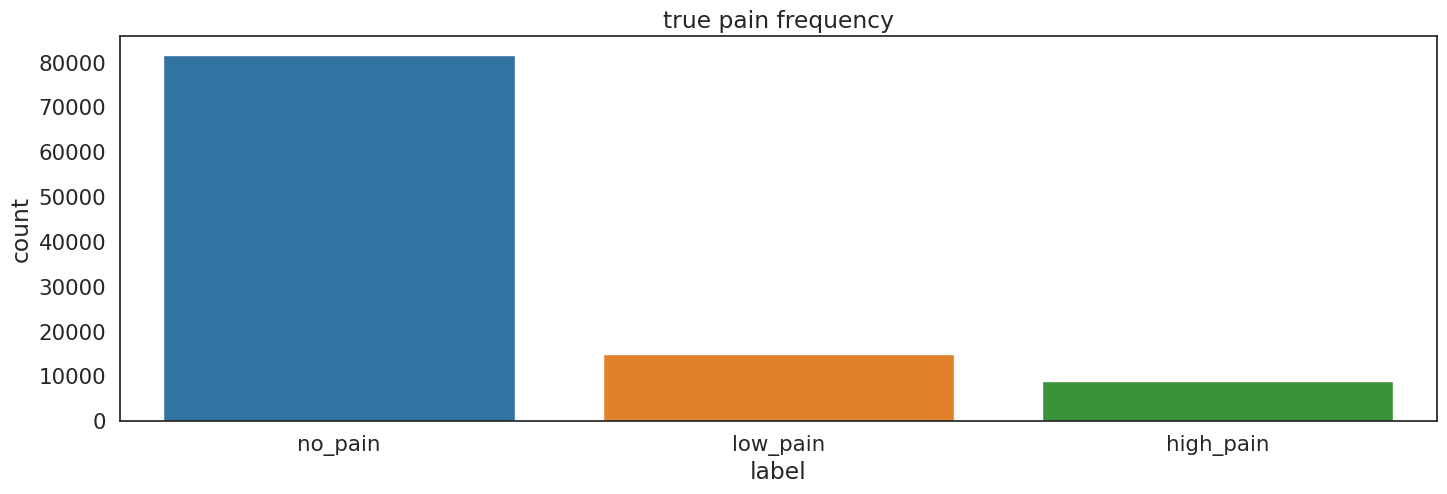

In [10]:
# Visualise the count of timestamps for each pain levelel
plt.figure(figsize=(17, 5))
sns.countplot(
    x='label',
    data=df,
    order=df['label'].value_counts().index,
    palette='tab10'
)
plt.title('true pain frequency')
plt.show()

Number of unique users: 661


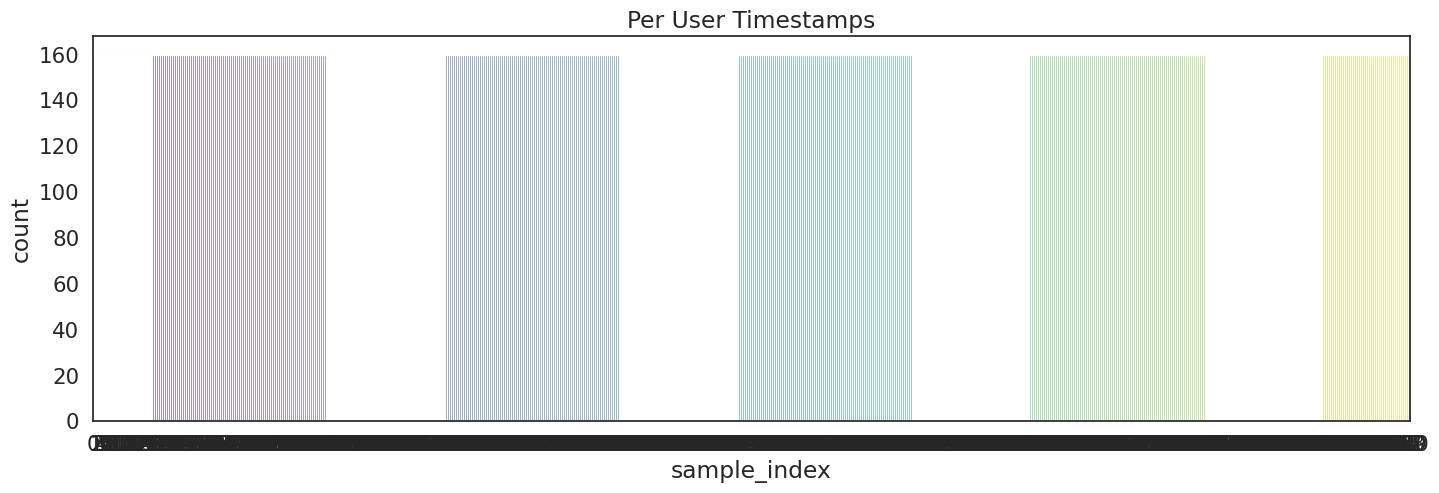

In [11]:
# Count the number of unique users
n_users = len(df['sample_index'].unique())
print(f"Number of unique users: {n_users}")

# Create a custom colour map with distinct colours for each user
colors = plt.cm.viridis(np.linspace(0, 1, n_users))

# Visualise the count of timestamps for each user
plt.figure(figsize=(17, 5))
sns.countplot(
    x='sample_index',
    data=df,
    palette=colors
)

# Set the title of the plot
plt.title('Per User Timestamps')

# Display the plot
plt.show()

##### Distribution of `n_legs`, `n_hands`, and `n_eyes` by Label

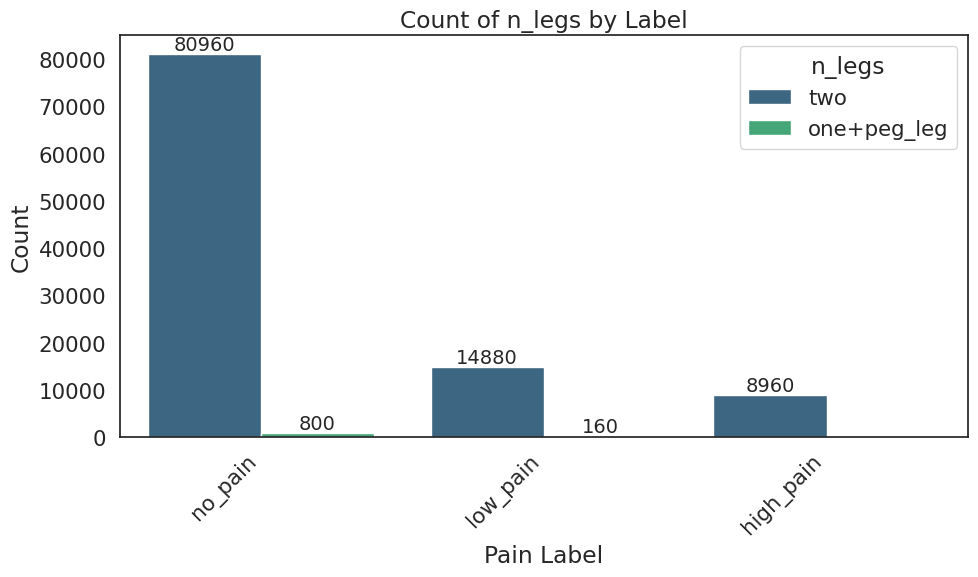

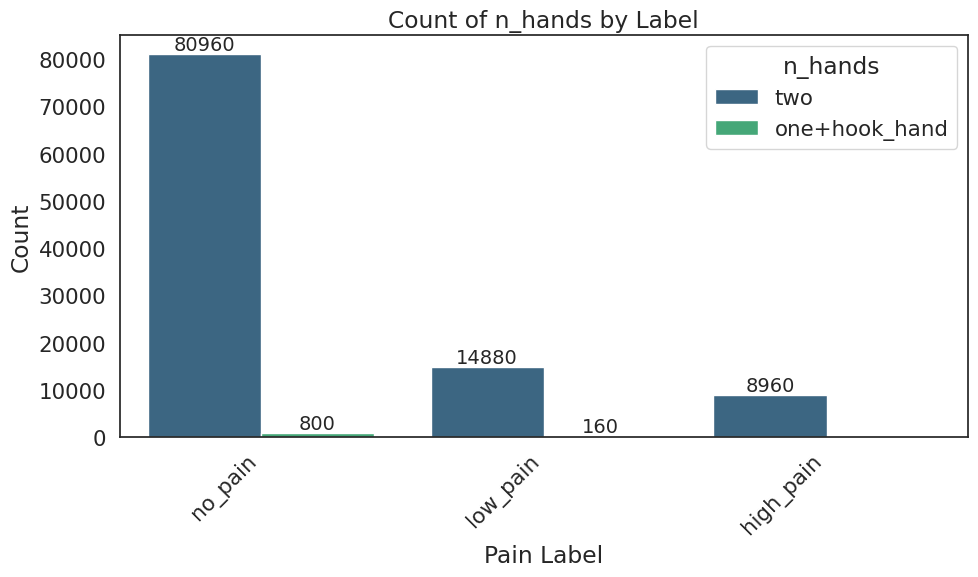

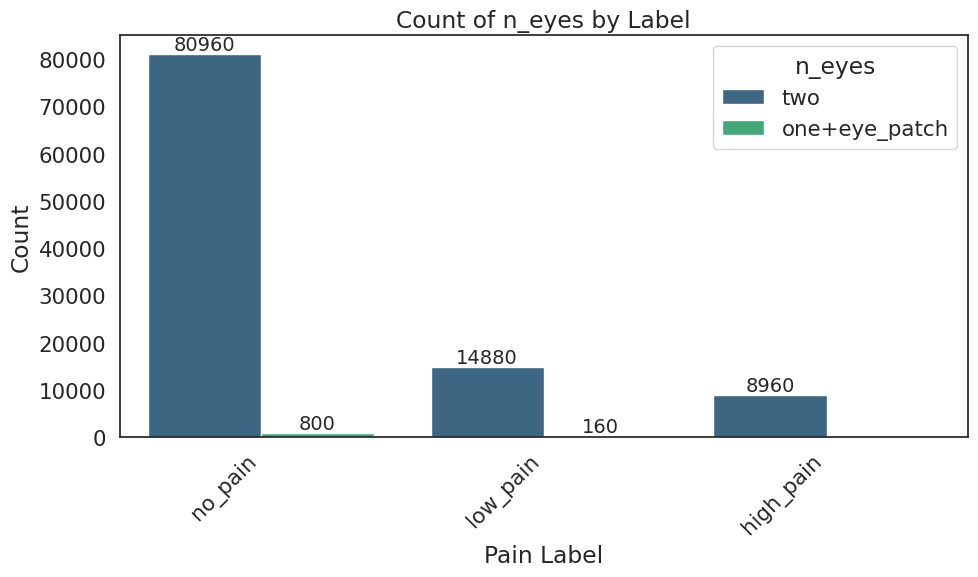

In [12]:
#plot to show number of invalid pirates
categorical_features = ['n_legs', 'n_hands', 'n_eyes']

for feature in categorical_features:
    plt.figure(figsize=(10, 6))
    ax = sns.countplot(data=df, x='label', hue=feature, palette='viridis')
    plt.title(f'Count of {feature} by Label')
    plt.xlabel('Pain Label')
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.legend(title=feature)

    # Add count labels on top of each bar
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f')

    plt.tight_layout()
    plt.show()

In [13]:
# Define a function to inspect sensor data for a specific pain level
def inspect_label(label, df, n_users=None, max_timesteps_per_user=160):
    joint_columns = [col for col in df.columns if col.startswith('pain_survey')]

    # Filter the DataFrame for the specified label
    labeled_data = df[df['label'] == label]

    unique_sample_indices = labeled_data['sample_index'].unique()
    if n_users is not None:
        # Select data only from the first n_users unique sample_indices
        selected_sample_indices = unique_sample_indices[:n_users]
    else:
        # If n_users is not specified, use all unique sample_indices for the label
        selected_sample_indices = unique_sample_indices

    if len(selected_sample_indices) == 0:
        print(f"No users found for label '{label}' with the given criteria.")
        return

    # Determine grid size for subplots
    num_joints = len(joint_columns)
    ncols = 4 # Number of columns in the subplot grid
    nrows = (num_joints + ncols - 1) // ncols # Calculate rows needed (ceiling division)

    # Create a figure and a grid of subplots
    # sharex=True ensures that all subplots share the same x-axis (time)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows), sharex=True)
    axes = axes.flatten() # Flatten the 2D array of axes for easier iteration

    # Set a main title for the entire figure
    fig.suptitle(f'Sensor Data for Label: {label} (showing {len(selected_sample_indices)} users)', y=1.02)

    # Iterate through each joint column to create its own subplot
    for i, joint_col in enumerate(joint_columns):
        if i >= len(axes): # Stop if we run out of allocated axes (e.g., if num_joints < nrows*ncols)
            break
        ax = axes[i]
        ax.set_title(joint_col, fontsize='medium') # Set title for individual joint plot
        # ax.set_xlabel('Time Step') # X-label only on bottom row if sharex=True is used
        # ax.set_ylabel('Value') # Y-label only on left-most column

        # Iterate through each selected user and plot their data for the current joint
        for user_idx in selected_sample_indices:
            user_data = labeled_data[labeled_data['sample_index'] == user_idx]
            # Apply max_timesteps_per_user limit if specified
            if max_timesteps_per_user is not None:
                user_data = user_data.head(max_timesteps_per_user)

            if not user_data.empty:
                ax.plot(user_data['time'], user_data[joint_col], label=f'User {user_idx}')

        ax.legend(loc='best', fontsize='x-small') # Add legend for each user in each joint plot
        ax.grid(True, linestyle='--', alpha=0.6) # Add a grid for readability

    # Hide any unused subplots in the grid
    for j in range(i + 1, len(axes)): # Loop from the next axis after the last plotted joint
        fig.delaxes(axes[j])

    # Adjust layout to prevent overlapping titles/labels, leaving space for the suptitle
    plt.tight_layout(rect=[0, 0.03, 1, 0.98])
    plt.show()

### Inspecting Sensor Data for Pirates with Specific Characteristics (2 legs, 2 hands, 2 eyes)

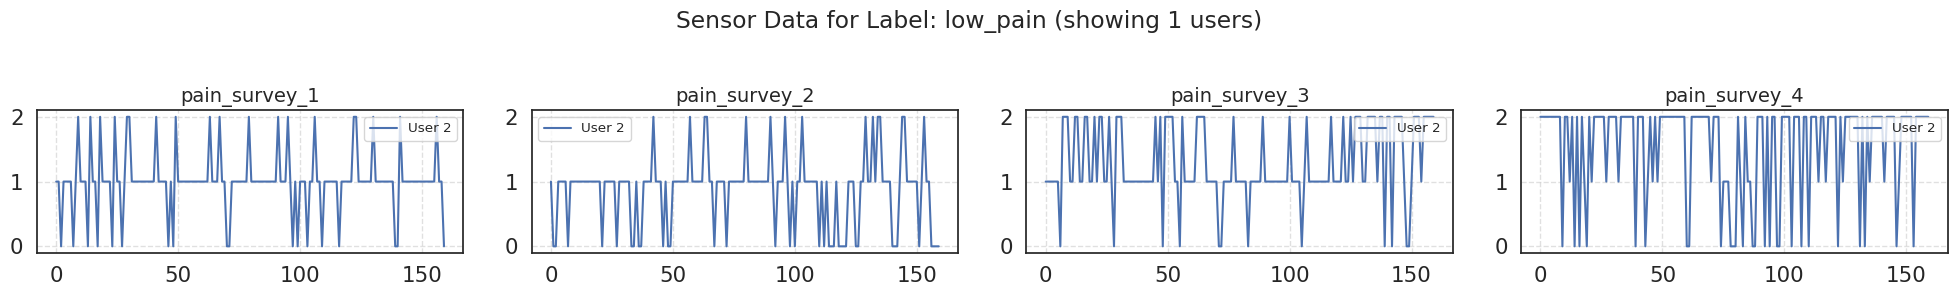

In [14]:
inspect_label('low_pain', df, 1)

Shape of filtered DataFrame: (104800, 42)


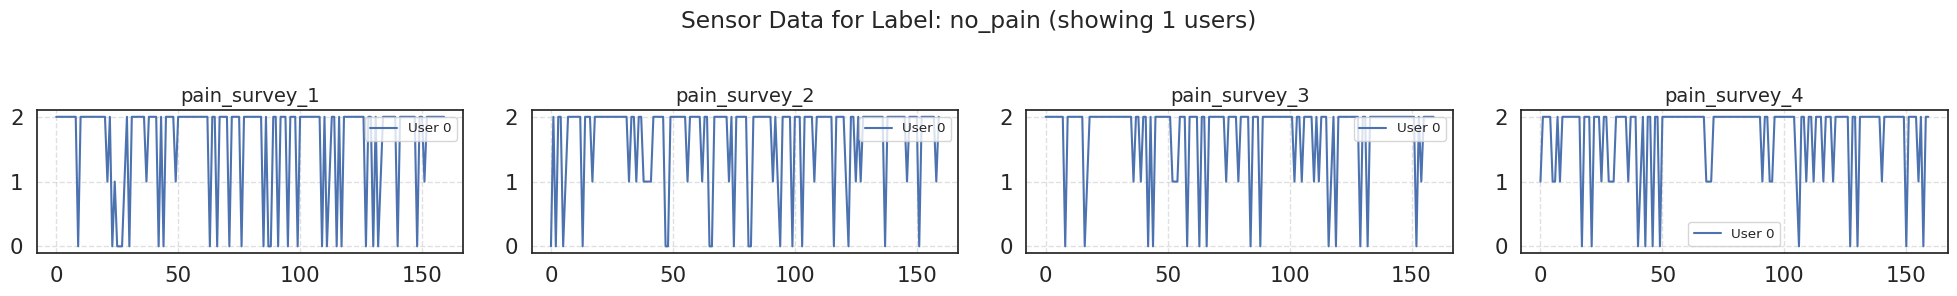

In [15]:
# Filter the DataFrame for pirates with 'two' legs, 'two' hands, and 'two' eyes
filtered_df_specific_pirates = df[
    (df['n_legs'] == 'two') &
    (df['n_hands'] == 'two') &
    (df['n_eyes'] == 'two')
]

print(f"Shape of filtered DataFrame: {filtered_df_specific_pirates.shape}")

# Inspect the 'no_pain' pain level for these filtered pirates
inspect_label('no_pain', filtered_df_specific_pirates, 1)

## 🥦 **Data Processing**

In [16]:
# Get unique user IDs and shuffle them, here we shuffle only based on pain level, in future experiment we introduced the stratification also based on has_any_disabilities
unique_users = df['sample_index'].unique()

random.seed(SEED) # Ensure reproducibility of shuffling
random.shuffle(unique_users)



# Calculate the number of users for the training set
n_train_users = len(unique_users) - N_VAL_USERS

# Split the shuffled user IDs into training, validation, and test sets
train_users = unique_users[:n_train_users]
val_users = unique_users[n_train_users:n_train_users + N_VAL_USERS]


# Split the dataset into training, validation, and test sets based on user IDs
df_train = df[df['sample_index'].isin(train_users)]
df_val = df[df['sample_index'].isin(val_users)]
df_test = dfTest

# Print the shapes of the training, validation, and test sets
print(f'Training set shape: {df_train.shape}')
print(f'Validation set shape: {df_val.shape}')
print(f'Test set shape: {df_test.shape}')

Training set shape: (89760, 42)
Validation set shape: (16000, 42)
Test set shape: (211840, 41)


In [17]:
# Initialise a dictionary to count occurrences of each pain level in the training set
training_labels = {
   'no_pain':0,
   'low_pain':0,
   'high_pain':0
}

# Count occurrences of each pain level for unique IDs in the training set
for id in df_train['sample_index'].unique():
    label = df_train[df_train['sample_index'] == id]['label'].values[0]
    training_labels[label] += 1

# Print the distribution of training labels
print('Training labels:', training_labels)

Training labels: {'no_pain': 435, 'low_pain': 79, 'high_pain': 47}


In [18]:
# Initialise a dictionary to count occurrences of each pain level in the validation set
val_labels = {
   'no_pain':0,
   'low_pain':0,
   'high_pain':0
}

# Count occurrences of each pain level for unique IDs in the validation set
for id in df_val['sample_index'].unique():
    label = df_val[df_val['sample_index'] == id]['label'].values[0]
    val_labels[label] += 1

# Print the distribution of validation labels
print('Validation labels:', val_labels)

Validation labels: {'no_pain': 76, 'low_pain': 15, 'high_pain': 9}


In [19]:
# Define a mapping of label names to integer labels
label_mapping = {
     'no_pain':0,
   'low_pain':1,
   'high_pain':2
}

# Map pain level names to integers in the training set
df_train['label'] = df_train['label'].map(label_mapping)

# Map pain level names to integers in the validation set
df_val['label'] = df_val['label'].map(label_mapping)

'''# Map pain level names to integers in the test set
df_test['label'] = df_test['label'].map(label_mapping)'''

"# Map pain level names to integers in the test set\ndf_test['label'] = df_test['label'].map(label_mapping)"

In [20]:
# Define the columns to be normalised
scale_columns = []
for col in df_train.columns:
    if col.startswith('joint_'):
        scale_columns.append(col)

# Calculate the minimum and maximum values from the training data only
mins = df_train[scale_columns].min()
maxs = df_train[scale_columns].max()

# Apply normalisation to the specified columns in all datasets
for column in scale_columns:
    col_min = mins[column]
    col_max = maxs[column]

    # Check for constant columns to prevent division by zero
    if col_max == col_min:
        print(f"Warning: Column '{column}' has constant values in df_train. Setting to 0 after 'normalization'.")
        df_train[column] = 0.0
        df_val[column] = 0.0
        df_test[column] = 0.0
    else:

        df_train[column] = (df_train[column] - col_min) / (col_max - col_min)

        df_val[column] = (df_val[column] - col_min) / (col_max - col_min)

        df_test[column] = (df_test[column] - col_min) / (col_max - col_min)

In [21]:
def build_sequences(df, window=160, stride=10):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []
    labels = []

    # Check if the 'label' column exists in the DataFrame
    has_labels = 'label' in df.columns

    # Define feature columns dynamically based on the dataframe structure
    feature_columns = [col for col in df.columns if col.startswith('pain_survey_')] + \
                      [col for col in df.columns if col.startswith('joint_')] + \
                      ['has_any_disability']

    num_features = len(feature_columns)

    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][feature_columns].values

        # Retrieve the pain level label for the current ID if labels are available
        current_label = None
        if has_labels:
            current_label = df[df['sample_index'] == id]['label'].values[0]
        else:
            # For test data where labels are not available, use a dummy value (e.g., 0)
            # This placeholder will be replaced by predictions later.
            current_label = 0

        # Calculate padding length to ensure full windows
        padding_len = (window - (len(temp) % window)) % window

        # Create zero padding and concatenate with the data
        padding = np.zeros((padding_len, num_features), dtype='float32')
        temp = np.concatenate((temp, padding))

        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            labels.append(current_label) # Append the actual label or the dummy label
            idx += stride

    # Convert lists to numpy arrays for further processing
    dataset = np.array(dataset)
    labels = np.array(labels)

    return dataset, labels

In [22]:
# Generate sequences and labels for the training set
X_train, y_train = build_sequences(df_train, WINDOW_SIZE, STRIDE)


# Generate sequences and labels for the validation set
X_val, y_val = build_sequences(df_val, WINDOW_SIZE, STRIDE)


# Generate sequences and labels for the test set
X_test, y_test = build_sequences(df_test, WINDOW_SIZE, STRIDE)


In [23]:
# Define the input shape based on the training data
input_shape = X_train.shape[1:]

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(y_train))

In [24]:
# Convert numpy arrays to PyTorch datasets (pairs features with labels)
# Explicitly cast to .float() to ensure torch.float32 type for all input tensors
train_ds = TensorDataset(torch.from_numpy(X_train).float(), torch.from_numpy(y_train))
val_ds   = TensorDataset(torch.from_numpy(X_val).float(), torch.from_numpy(y_val))
test_ds  = TensorDataset(torch.from_numpy(X_test).float(), torch.from_numpy(y_test))

In [25]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [26]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

## 🔧 **Finally building the model**

In [27]:
def recurrent_summary(model, input_size):
    """
    Custom summary function that emulates torchinfo's output while correctly
    counting parameters for RNN/GRU/LSTM layers.

    This function is designed for models whose direct children are
    nn.Linear, nn.RNN, nn.GRU, or nn.LSTM layers.

    Args:
        model (nn.Module): The model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    # Dictionary to store output shapes captured by forward hooks
    output_shapes = {}
    # List to track hook handles for later removal
    hooks = []

    def get_hook(name):
        """Factory function to create a forward hook for a specific module."""
        def hook(module, input, output):
            # Handle RNN layer outputs (returns a tuple)
            if isinstance(output, tuple):
                # output[0]: all hidden states with shape (batch, seq_len, hidden*directions)
                shape1 = list(output[0].shape)
                shape1[0] = -1  # Replace batch dimension with -1

                # output[1]: final hidden state h_n (or tuple (h_n, c_n) for LSTM)
                if isinstance(output[1], tuple):  # LSTM case: (h_n, c_n)
                    shape2 = list(output[1][0].shape)  # Extract h_n only
                else:  # RNN/GRU case: h_n only
                    shape2 = list(output[1].shape)

                # Replace batch dimension (middle position) with -1
                shape2[1] = -1

                output_shapes[name] = f"[{shape1}, {shape2}]"

            # Handle standard layer outputs (e.g., Linear)
            else:
                shape = list(output.shape)
                shape[0] = -1  # Replace batch dimension with -1
                output_shapes[name] = f"{shape}"
        return hook

    # 1. Determine the device where model parameters reside
    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")  # Fallback for models without parameters

    # 2. Create a dummy input tensor with batch_size=1
    dummy_input = torch.randn(1, *input_size).to(device)

    # 3. Register forward hooks on target layers
    # Iterate through direct children of the model (e.g., self.rnn, self.classifier)
    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.RNN, nn.GRU, nn.LSTM)):
            # Register the hook and store its handle for cleanup
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    # 4. Execute a dummy forward pass in evaluation mode
    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            # Clean up hooks even if an error occurs
            for h in hooks:
                h.remove()
            return

    # 5. Remove all registered hooks
    for h in hooks:
        h.remove()

    # --- 6. Print the summary table ---

    print("-" * 79)
    # Column headers
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Iterate through modules again to collect and display parameter information
    for name, module in model.named_children():
        if name in output_shapes:
            # Count total and trainable parameters for this module
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            # Format strings for display
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)

In [28]:
class RecurrentClassifier(nn.Module):
    """
    Generic RNN classifier (RNN, LSTM, GRU).
    Uses the last hidden state for classification.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            num_layers,
            num_classes,
            rnn_type='LSTM',        # 'RNN', 'LSTM', or 'GRU'
            bidirectional=False,
            dropout_rate=0.2
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional

        # Map string name to PyTorch RNN class
        rnn_map = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        if rnn_type not in rnn_map:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        rnn_module = rnn_map[rnn_type]

        # Dropout is only applied between layers (if num_layers > 1)
        dropout_val = dropout_rate if num_layers > 1 else 0

        # Create the recurrent layer
        self.rnn = rnn_module(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,       # Input shape: (batch, seq_len, features)
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        # Calculate input size for the final classifier
        if self.bidirectional:
            classifier_input_size = hidden_size * 2 # Concat fwd + bwd
        else:
            classifier_input_size = hidden_size

        # Final classification layer
        self.classifier = nn.Linear(classifier_input_size, num_classes)

    def forward(self, x):
        """
        x shape: (batch_size, seq_length, input_size)
        """

        # rnn_out shape: (batch_size, seq_len, hidden_size * num_directions)
        rnn_out, hidden = self.rnn(x)

        # LSTM returns (h_n, c_n), we only need h_n
        if self.rnn_type == 'LSTM':
            hidden = hidden[0]

        # hidden shape: (num_layers * num_directions, batch_size, hidden_size)

        if self.bidirectional:
            # Reshape to (num_layers, 2, batch_size, hidden_size)
            hidden = hidden.view(self.num_layers, 2, -1, self.hidden_size)

            # Concat last fwd (hidden[-1, 0, ...]) and bwd (hidden[-1, 1, ...])
            # Final shape: (batch_size, hidden_size * 2)
            hidden_to_classify = torch.cat([hidden[-1, 0, :, :], hidden[-1, 1, :, :]], dim=1)
        else:
            # Take the last layer's hidden state
            # Final shape: (batch_size, hidden_size)
            hidden_to_classify = hidden[-1]

        # Get logits
        logits = self.classifier(hidden_to_classify)
        return logits




## 🧠 LSTM

In [29]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

# Set up loss function and optimizer
criterion = nn.CrossEntropyLoss()

In [30]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU) and ensure float32 type for inputs
        inputs, targets = inputs.to(device).float(), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()

        # Unscale the gradients before clipping, then clip
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # Apply gradient clipping

        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [31]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device and ensure float32 type for inputs
            inputs, targets = inputs.to(device).float(), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [32]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Log weights
            if param.numel() > 0:
                # Detach, move to CPU, convert to numpy, filter finite values
                finite_weights = param.data.detach().cpu().numpy()
                finite_weights = finite_weights[np.isfinite(finite_weights)]
                if finite_weights.size > 0: # Only add histogram if there are finite values
                    writer.add_histogram(f'{name}/weights', finite_weights, epoch)

            # Log gradients
            if param.grad is not None and param.grad.numel() > 0:
                # Detach, move to CPU, convert to numpy, filter finite values
                finite_gradients = param.grad.data.detach().cpu().numpy()
                finite_gradients = finite_gradients[np.isfinite(finite_gradients)]
                if finite_gradients.size > 0: # Only add histogram if there are finite values
                    writer.add_histogram(f'{name}/gradients', finite_gradients, epoch)

In [33]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler,
        device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1",
        mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name="",
        scheduler=None): # Added scheduler as an argument
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")
        scheduler (torch.optim.lr_scheduler._LRScheduler, optional): Learning rate scheduler (default: None)

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': [],
        'lr': [] # To track learning rate
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)
        training_history['lr'].append(optimizer.param_groups[0]['lr']) # Log current LR

        # Step the learning rate scheduler
        if scheduler is not None:
            # ReduceLROnPlateau needs the metric
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                metric_to_monitor = val_f1 if mode == 'max' else val_loss
                scheduler.step(metric_to_monitor)
            else:
                # Other schedulers like CosineAnnealingLR or StepLR just step per epoch
                scheduler.step()


        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )
            writer.add_scalar('Learning Rate', optimizer.param_groups[0]['lr'], epoch) # Log LR to TensorBoard

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f} | "
                    f"LR={optimizer.param_groups[0]['lr']:.6f}") # Print LR

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("./models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        current_time = datetime.datetime.now().strftime('%Y%m%d-%H%M%S')
        torch.save(model.state_dict(), "./models/history/"+current_time+experiment_name+'_model.pt')
        torch.save(model.state_dict(), "./models/"+experiment_name+'_model.pt')

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

In [34]:
# Create model and display architecture with parameter count
rnn_model = RecurrentClassifier(
    input_size=input_shape[-1], # Pass the number of features
    hidden_size=HIDDEN_SIZE,
    num_layers=HIDDEN_LAYERS,
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    bidirectional=True,
    rnn_type='LSTM'
    ).to(device)
recurrent_summary(rnn_model, input_size=input_shape)

# Set up TensorBoard logging and save model architecture
experiment_name = "lstm"
current_time = datetime.datetime.now().strftime('%Y%m%d-%H%M%S')
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name+current_time)
x = torch.randn(1, input_shape[0], input_shape[1]).to(device)
writer.add_graph(rnn_model, x)

# Define optimizer with L2 regularization
optimizer = torch.optim.AdamW(rnn_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
rnn (LSTM)                [[-1, 45, 256], [4, -1, 128]] 565,248        
classifier (Linear)       [-1, 3]                      771            
Total params: 566,019
Trainable params: 566,019
Non-trainable params: 0
-------------------------------------------------------------------------------


## ♟ **Actual training**

In [35]:
%%time
# Train model and track training history
rnn_model, training_history = fit(
    model=rnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name="bi_lstm",
    patience=PATIENCE
    )

# Update best model if current performance is superior
if training_history['val_f1'][-1] > best_performance:
    best_model = rnn_model
    best_performance = training_history['val_f1'][-1]

Training 500 epochs...
Epoch   1/500 | Train: Loss=0.5990, F1 Score=0.7408 | Val: Loss=0.6484, F1 Score=0.6842 | LR=0.001000
Epoch   2/500 | Train: Loss=0.4571, F1 Score=0.8239 | Val: Loss=0.5111, F1 Score=0.8325 | LR=0.001000
Epoch   3/500 | Train: Loss=0.3578, F1 Score=0.8776 | Val: Loss=0.4172, F1 Score=0.8668 | LR=0.001000
Epoch   4/500 | Train: Loss=0.3241, F1 Score=0.8958 | Val: Loss=0.4540, F1 Score=0.8532 | LR=0.001000
Epoch   5/500 | Train: Loss=0.2648, F1 Score=0.9117 | Val: Loss=0.6684, F1 Score=0.8221 | LR=0.001000
Epoch   6/500 | Train: Loss=0.2323, F1 Score=0.9227 | Val: Loss=0.4311, F1 Score=0.8769 | LR=0.001000
Epoch   7/500 | Train: Loss=0.2218, F1 Score=0.9288 | Val: Loss=0.3386, F1 Score=0.9126 | LR=0.001000
Epoch   8/500 | Train: Loss=0.1913, F1 Score=0.9379 | Val: Loss=0.3926, F1 Score=0.8844 | LR=0.001000
Epoch   9/500 | Train: Loss=0.1822, F1 Score=0.9419 | Val: Loss=0.3514, F1 Score=0.9067 | LR=0.001000
Epoch  10/500 | Train: Loss=0.1546, F1 Score=0.9490 | Val: 

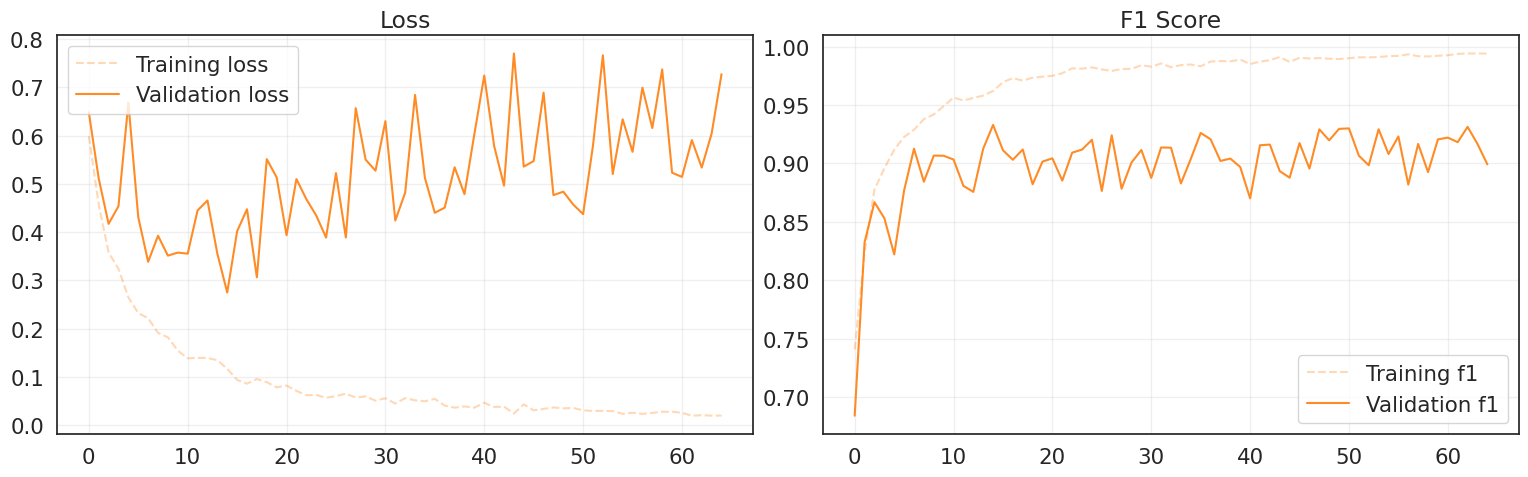

In [36]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.9357
Precision over the validation set: 0.9343
Recall over the validation set: 0.9357
F1 score over the validation set: 0.9330


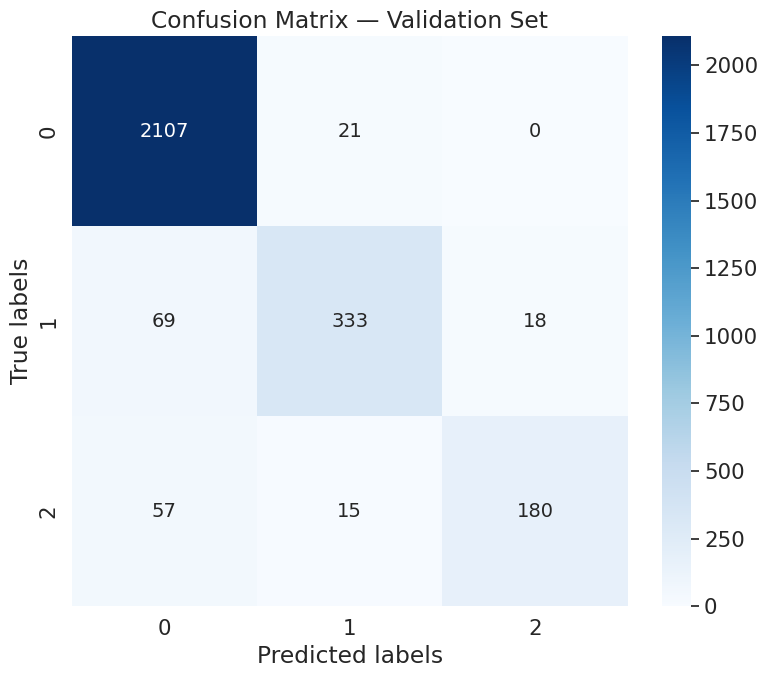

In [37]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device).float()  # Explicitly cast to float32

        # Forward pass: get model predictions
        logits = rnn_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

## 🍇 Using the best model to classify the test datase

In [38]:
rnn_model = RecurrentClassifier(
    input_size=input_shape[-1],
    hidden_size=HIDDEN_SIZE,
    num_layers=HIDDEN_LAYERS,
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    bidirectional=True,
    rnn_type='LSTM'
).to(device)
rnn_model.load_state_dict(torch.load('models/bi_lstm_model.pt'))

print("Best performing LSTM model loaded successfully.")

Best performing LSTM model loaded successfully.


In [39]:
all_test_predictions = []
rnn_model.eval() # Ensure model is in evaluation mode
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device).float()
        logits = rnn_model(xb)
        predictions = logits.argmax(dim=1).cpu().numpy()
        all_test_predictions.append(predictions)

# Concatenate all predictions
all_test_predictions = np.concatenate(all_test_predictions)

print(f"Generated {len(all_test_predictions)} predictions for the test set.")

Generated 37072 predictions for the test set.


In [40]:
label_inverse_mapping = {v: k for k, v in label_mapping.items()}

# Create a DataFrame to store test predictions along with their original sample_index
test_pred_df = pd.DataFrame({
    'sample_index_sequence': range(len(all_test_predictions)), # Create a unique ID for each sequence
    'predicted_label_int': all_test_predictions
})

# Map integer predictions back to string labels
test_pred_df['predicted_label_str'] = test_pred_df['predicted_label_int'].map(label_inverse_mapping)

print(test_pred_df.head())


   sample_index_sequence  predicted_label_int predicted_label_str
0                      0                    1            low_pain
1                      1                    1            low_pain
2                      2                    1            low_pain
3                      3                    0             no_pain
4                      4                    0             no_pain


In [41]:
def get_sample_indices_for_sequences(df, window, stride):
    sample_indices = []
    for uid in df['sample_index'].unique():
        user_df = df[df['sample_index'] == uid]
        num_timesteps = len(user_df)

        # Calculate number of sequences generated for this user, similar to build_sequences
        # Need to consider padding that was applied in build_sequences
        padding_len = (window - (num_timesteps % window)) % window
        padded_num_timesteps = num_timesteps + padding_len

        idx = 0
        while idx + window <= padded_num_timesteps:
            sample_indices.append(uid)
            idx += stride
    return np.array(sample_indices)

# Get the original sample_index for each sequence generated for X_test
test_seq_original_sample_indices = get_sample_indices_for_sequences(df_test, WINDOW_SIZE, STRIDE)

# Verify that the number of original sample indices matches the number of predictions
assert len(test_seq_original_sample_indices) == len(all_test_predictions), \
    "Mismatch between number of sequences and number of predictions."

# Create a DataFrame that maps predictions to their original sample_index
predictions_with_original_index_df = pd.DataFrame({
    'sample_index': test_seq_original_sample_indices,
    'predicted_label_int': all_test_predictions
})

# Map integer predictions back to string labels
predictions_with_original_index_df['predicted_label_str'] = predictions_with_original_index_df['predicted_label_int'].map(label_inverse_mapping)

print("Predictions mapped to original sample indices:")
print(predictions_with_original_index_df.head())
print("\nDataFrame Info:")
predictions_with_original_index_df.info()

Predictions mapped to original sample indices:
   sample_index  predicted_label_int predicted_label_str
0             0                    1            low_pain
1             0                    1            low_pain
2             0                    1            low_pain
3             0                    0             no_pain
4             0                    0             no_pain

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37072 entries, 0 to 37071
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   sample_index         37072 non-null  int64 
 1   predicted_label_int  37072 non-null  int64 
 2   predicted_label_str  37072 non-null  object
dtypes: int64(2), object(1)
memory usage: 869.0+ KB


In [43]:
def get_sample_indices_for_sequences(df, window, stride):
    sample_indices = []
    # Feature columns are needed only to determine the number of original timesteps per user
    feature_columns = [col for col in df.columns if col.startswith('pain_survey_')] + \
                      [col for col in df.columns if col.startswith('joint_')] + \
                      ['has_any_disability']

    for uid in df['sample_index'].unique():
        user_df = df[df['sample_index'] == uid]
        num_timesteps = len(user_df) # This is the effective length of `temp` before padding in build_sequences

        # Calculate padding length consistent with build_sequences logic
        padding_len = (window - (num_timesteps % window)) % window

        # Total length of the series after conceptual padding
        total_len_after_padding = num_timesteps + padding_len

        idx = 0
        while idx + window <= total_len_after_padding:
            sample_indices.append(uid)
            idx += stride
    return np.array(sample_indices)

# Corrected window and stride based on the actual number of sequences generated for X_test
# (1300 sequences for 100 users with 160 timesteps each implies 13 sequences/user).
# For 160 timesteps, window=40, stride=10 produces (160 - 40) / 10 + 1 = 13 sequences.
# The `X_test` was generated using the global `WINDOW_SIZE` and `STRIDE`.
window_for_test_seq_gen = WINDOW_SIZE # Use the global WINDOW_SIZE (45)
stride_for_test_seq_gen = STRIDE # Use the global STRIDE (5)

# Get the original sample_index for each sequence generated for X_test
test_seq_original_sample_indices = get_sample_indices_for_sequences(df_test, window_for_test_seq_gen, stride_for_test_seq_gen)

# Verify that the number of original sample indices matches the number of predictions
assert len(test_seq_original_sample_indices) == len(all_test_predictions), \
    "Mismatch between number of sequences and number of predictions."

# Create a DataFrame that maps predictions to their original sample_index
predictions_with_original_index_df = pd.DataFrame({
    'sample_index': test_seq_original_sample_indices,
    'predicted_label_int': all_test_predictions
})

# Map integer predictions back to string labels
predictions_with_original_index_df['predicted_label_str'] = predictions_with_original_index_df['predicted_label_int'].map(label_inverse_mapping)

print("Predictions mapped to original sample indices:")
print(predictions_with_original_index_df.head())
print("\nDataFrame Info:")
predictions_with_original_index_df.info()

Predictions mapped to original sample indices:
   sample_index  predicted_label_int predicted_label_str
0             0                    1            low_pain
1             0                    1            low_pain
2             0                    1            low_pain
3             0                    0             no_pain
4             0                    0             no_pain

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37072 entries, 0 to 37071
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   sample_index         37072 non-null  int64 
 1   predicted_label_int  37072 non-null  int64 
 2   predicted_label_str  37072 non-null  object
dtypes: int64(2), object(1)
memory usage: 869.0+ KB


In [44]:
final_predictions = predictions_with_original_index_df.groupby('sample_index')['predicted_label_str'].agg(lambda x: x.mode()[0]).reset_index()

# Rename the columns to match the submission format
final_predictions.columns = ['sample_index', 'label']

# Format sample_index to have 3 digits, padded with leading zeros
final_predictions['sample_index'] = final_predictions['sample_index'].astype(str).str.zfill(3)


print("Final predictions grouped by sample_index:")
print(final_predictions.head())
print("\nDataFrame Info:")
final_predictions.info()

Final predictions grouped by sample_index:
  sample_index    label
0          000  no_pain
1          001  no_pain
2          002  no_pain
3          003  no_pain
4          004  no_pain

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1324 entries, 0 to 1323
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   sample_index  1324 non-null   object
 1   label         1324 non-null   object
dtypes: object(2)
memory usage: 20.8+ KB


In [45]:
final_predictions.to_csv('submission.csv', index=False)
print("submission.csv created successfully.")

submission.csv created successfully.


# Improved RNN version with Focus Loss function, weighted loader and dinamic learning rate

## Reload the dataset, and aplly some different transformations used by the second model: like turning the timestamp in a cosine/sine function, trying to extrapolate some form of recurrency


In [46]:


#read the dataset

df = pd.read_csv('dataset/pirate_pain_train.csv')
dfTest = pd.read_csv('dataset/pirate_pain_test.csv')

# replace with  pirate? 1:0, i just wanted to
df['has_any_disability'] = ((df['n_legs'] != 'two') | (df['n_hands'] != 'two') | (df['n_eyes'] != 'two')).astype(int)
dfTest['has_any_disability'] = ((dfTest['n_legs'] != 'two') | (dfTest['n_hands'] != 'two') | (dfTest['n_eyes'] != 'two')).astype(int)

# Calculate 'hour_of_day' assuming 'time' unit is an hour and loops every 24 hours
df['hour_of_day'] = df['time'] % TIME
dfTest['hour_of_day'] = dfTest['time'] % TIME

# Apply sine and cosine transformations for cyclical representation
df['hour_sin'] = np.sin(2 * np.pi * df['hour_of_day'] / TIME)
df['hour_cos'] = np.cos(2 * np.pi * df['hour_of_day'] / TIME)
dfTest['hour_sin'] = np.sin(2 * np.pi * dfTest['hour_of_day'] / TIME)
dfTest['hour_cos'] = np.cos(2 * np.pi * dfTest['hour_of_day'] / TIME)

#turn float64 into float32, to speed up
joint_columns = [col for col in df.columns if col.startswith('joint_')]
df[joint_columns] = df[joint_columns].astype(np.float32)

I know I know I should have followed the instuctions

In [47]:

labels_df = pd.read_csv('dataset/pirate_pain_train_labels.csv')
df = pd.merge(df, labels_df, on='sample_index', how='left')


In [48]:
# Define the columns to be normalised
scale_columns = []
for col in df_train.columns:
    if col.startswith('joint_'):
        scale_columns.append(col)

# Calculate the minimum and maximum values from the training data only
mins = df_train[scale_columns].min()
maxs = df_train[scale_columns].max()

# Apply normalisation to the specified columns in all datasets
for column in scale_columns:
    col_min = mins[column]
    col_max = maxs[column]

    # Check for constant columns to prevent division by zero
    if col_max == col_min:
        print(f"Warning: Column '{column}' has constant values in df_train. Setting to 0 after 'normalization'.")
        df_train[column] = 0.0
        df_val[column] = 0.0
        df_test[column] = 0.0
    else:

        df_train[column] = (df_train[column] - col_min) / (col_max - col_min)

        df_val[column] = (df_val[column] - col_min) / (col_max - col_min)

        df_test[column] = (df_test[column] - col_min) / (col_max - col_min)

## Here we exploited a correlationj matrix to see how column 10 and 11 are correleted, and decided to drop one + column 30 that was constant

In [49]:
#dropping joint_30 and joint_11

df_train = df_train.drop(columns=['joint_30', 'joint_11'])
df_val = df_val.drop(columns=['joint_30', 'joint_11'])
df_test = df_test.drop(columns=['joint_30', 'joint_11'])


## weighted data sampler implementation and actual application

In [50]:
# here I need to create a weight vector with weights in correspondence of the train_ds samples
weights_vector = []

# Get user-level information (has_any_disability and original string label) from the full 'df' DataFrame
# This ensures we get the original string label before df_train's labels were mapped to integers.
user_level_info_df = df[df['sample_index'].isin(df_train['sample_index'].unique())]
user_level_info_df = user_level_info_df[['sample_index', 'has_any_disability', 'label']].drop_duplicates(subset=['sample_index']).set_index('sample_index')

# Calculate weights for 'pirate' users
pirate_users_info = user_level_info_df[user_level_info_df['has_any_disability'] == 1]
pirate_label_counts = pirate_users_info['label'].value_counts()
total_pirate_users = pirate_label_counts.sum()
# Calculate inverse frequency weights
weights_pirate = {
    label: (1.0 / count) * (total_pirate_users / len(pirate_label_counts))
    for label, count in pirate_label_counts.items()
}
# Normalize the weights so they sum to 1 for each category (optional, but good practice)
sum_weights_pirate = sum(weights_pirate.values())
weights_pirate = {label: weight / sum_weights_pirate for label, weight in weights_pirate.items()}


# Calculate weights for 'no_pirate' users
no_pirate_users_info = user_level_info_df[user_level_info_df['has_any_disability'] == 0]
no_pirate_label_counts = no_pirate_users_info['label'].value_counts()
total_no_pirate_users = no_pirate_label_counts.sum()
# Calculate inverse frequency weights
weights_no_pirate = {
    label: (1.0 / count) * (total_no_pirate_users / len(no_pirate_label_counts))
    for label, count in no_pirate_label_counts.items()
}
# Normalize the weights so they sum to 1 for each category (optional, but good practice)
sum_weights_no_pirate = sum(weights_no_pirate.values())
weights_no_pirate = {label: weight / sum_weights_no_pirate for label, weight in weights_no_pirate.items()}


# Reconstruct the mapping from sequence index in train_ds to its original sample_index (user_id)
# This follows the logic of the build_sequences function to identify which user each sequence belongs to.
original_sample_indices_for_train_sequences = []
for user_id in df_train['sample_index'].unique():
    # Get the length of the data for this user from df_train
    user_data_len = len(df_train[df_train['sample_index'] == user_id])

    # Padding logic from build_sequences function (using global WINDOW_SIZE and STRIDE)
    padding_len = (WINDOW_SIZE - (user_data_len % WINDOW_SIZE)) % WINDOW_SIZE
    total_len_after_padding = user_data_len + padding_len

    idx = 0
    while idx + WINDOW_SIZE <= total_len_after_padding:
        original_sample_indices_for_train_sequences.append(user_id)
        idx += STRIDE

# Verify the length match, crucial for WeightedRandomSampler
if len(original_sample_indices_for_train_sequences) != len(train_ds):
    raise ValueError(
        "Mismatch in number of sequences for weight calculation and actual train_ds length.\n"
        "This indicates an inconsistency in how sequences are generated or accounted for."
        f"Expected {len(train_ds)} sequences, but got {len(original_sample_indices_for_train_sequences)}."
    )


# Now iterate through the reconstructed sequence-to-user mapping and assign weights
for sequence_original_sample_index in original_sample_indices_for_train_sequences:
    # Retrieve user-level attributes using the original sample_index
    has_disability = user_level_info_df.loc[sequence_original_sample_index, 'has_any_disability']
    original_string_label = user_level_info_df.loc[sequence_original_sample_index, 'label']

    # Determine the weight based on disability status and the original string label
    if has_disability:
        weight = weights_pirate[original_string_label]
    else:
        weight = weights_no_pirate[original_string_label]

    weights_vector.append(weight)

# Convert the list of weights to a PyTorch tensor
weights_vector = torch.tensor(weights_vector, dtype=torch.float32)

print(weights_vector)

tensor([0.0637, 0.0637, 0.0637,  ..., 0.0637, 0.0637, 0.0637])


In [51]:
def make_loader(ds, batch_size, shuffle, drop_last, sampler=None):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = cpu_cores-1

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle and sampler is None,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=5,  # Load 4 batches ahead
        sampler=sampler
    )

In [52]:
# This sampler uses the pre-calculated weights_vector to balance classes during training
weighted_sampler = WeightedRandomSampler(weights=weights_vector, num_samples=len(train_ds), replacement=True)

train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, sampler=weighted_sampler)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

## **Focal Loss implementation**

In [53]:
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

        if isinstance(alpha, (float, int)): # Handle scalar alpha
            self.alpha = torch.tensor([alpha, 1 - alpha])
        if isinstance(alpha, torch.Tensor):
            self.alpha = alpha.to(device)

    def forward(self, inputs, targets):
        BCE_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-BCE_loss)
        F_loss = self.alpha[targets] * (1-pt)**self.gamma * BCE_loss

        if self.reduction == 'mean':
            return F_loss.mean()
        elif self.reduction == 'sum':
            return F_loss.sum()
        else:
            return F_loss

print("FocalLoss class defined.")

FocalLoss class defined.


##⛪ **Some train & validation funcions + actual building of correct architecture**


In [54]:
# Count the occurrences of each class in the training labels
class_counts = np.bincount(y_train)

# Calculate inverse frequency weights: higher weight for less frequent classes
# Add a small epsilon to avoid division by zero
class_weights = 1.0 / (class_counts + 1e-8)

# Normalize the weights
class_weights = class_weights / class_weights.sum() * num_classes

# Convert the numpy array of weights to a PyTorch tensor and move it to the correct device
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
print("Calculated Class Weights:", class_weights)

Calculated Class Weights: tensor([0.1903, 1.0480, 1.7616], device='cuda:0')


In [55]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')


In [56]:
CRITERION = FocalLoss(alpha=class_weights, gamma=GAMMA, reduction='mean')

In [57]:
# Create model and display architecture with parameter count
rnn_model = RecurrentClassifier(
    input_size=input_shape[-1], # Pass the number of features
    hidden_size=HIDDEN_SIZE,
    num_layers=HIDDEN_LAYERS,
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    bidirectional=BIDIRECTIONAL,
    rnn_type=ARCHITECTURE,

    ).to(device)
recurrent_summary(rnn_model, input_size=input_shape)

# Set up TensorBoard logging and save model architecture
experiment_name = f"{ARCHITECTURE}_{BIDIRECTIONAL}_ws{WINDOW_SIZE}_bs{BATCH_SIZE}_stride{STRIDE}_lr{LEARNING_RATE}"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_shape[0], input_shape[1]).to(device)
writer.add_graph(rnn_model, x)

# Define optimizer with L2 regularization
optimizer = torch.optim.AdamW(rnn_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)



# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Initialize ReduceLROnPlateau scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.1,
    patience=20,
    min_lr=1e-6
)

-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
rnn (LSTM)                [[-1, 45, 256], [4, -1, 128]] 565,248        
classifier (Linear)       [-1, 3]                      771            
Total params: 566,019
Trainable params: 566,019
Non-trainable params: 0
-------------------------------------------------------------------------------


## 📑 **Train the "mind" (you can avoid to run)**

In [58]:
%%time
# Train model and track training history
rnn_model, training_history = fit(
    model=rnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=CRITERION,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=10,
    l1_lambda=L1_LAMBDA,
    l2_lambda=L2_LAMBDA,
    #expreiment_name with all parameters
    experiment_name = f"{ARCHITECTURE}_{BIDIRECTIONAL}_ws{WINDOW_SIZE}_bs{BATCH_SIZE}_stride{STRIDE}_lr{LEARNING_RATE}_gamma{GAMMA}",
    patience=PATIENCE,
    scheduler=scheduler
    )

# Update best model if current performance is superior
if training_history['val_f1'][-1] > best_performance:
    best_model = rnn_model
    best_performance = training_history['val_f1'][-1]

Training 500 epochs...
Epoch   1/500 | Train: Loss=0.2228, F1 Score=0.3868 | Val: Loss=0.1760, F1 Score=0.0768 | LR=0.001000
Epoch  10/500 | Train: Loss=0.0191, F1 Score=0.9213 | Val: Loss=0.1372, F1 Score=0.8182 | LR=0.001000
Epoch  20/500 | Train: Loss=0.0084, F1 Score=0.9647 | Val: Loss=0.1096, F1 Score=0.8863 | LR=0.001000
Epoch  30/500 | Train: Loss=0.0045, F1 Score=0.9795 | Val: Loss=0.1849, F1 Score=0.8871 | LR=0.001000
Epoch  40/500 | Train: Loss=0.0057, F1 Score=0.9772 | Val: Loss=0.1985, F1 Score=0.9174 | LR=0.001000
Epoch  50/500 | Train: Loss=0.0036, F1 Score=0.9869 | Val: Loss=0.1698, F1 Score=0.9128 | LR=0.001000
Epoch  60/500 | Train: Loss=0.0005, F1 Score=0.9969 | Val: Loss=0.2458, F1 Score=0.9217 | LR=0.000100
Epoch  70/500 | Train: Loss=0.0002, F1 Score=0.9993 | Val: Loss=0.2629, F1 Score=0.9168 | LR=0.000100
Epoch  80/500 | Train: Loss=0.0001, F1 Score=0.9996 | Val: Loss=0.2861, F1 Score=0.9283 | LR=0.000010
Early stopping triggered after 86 epochs.
Best model restor

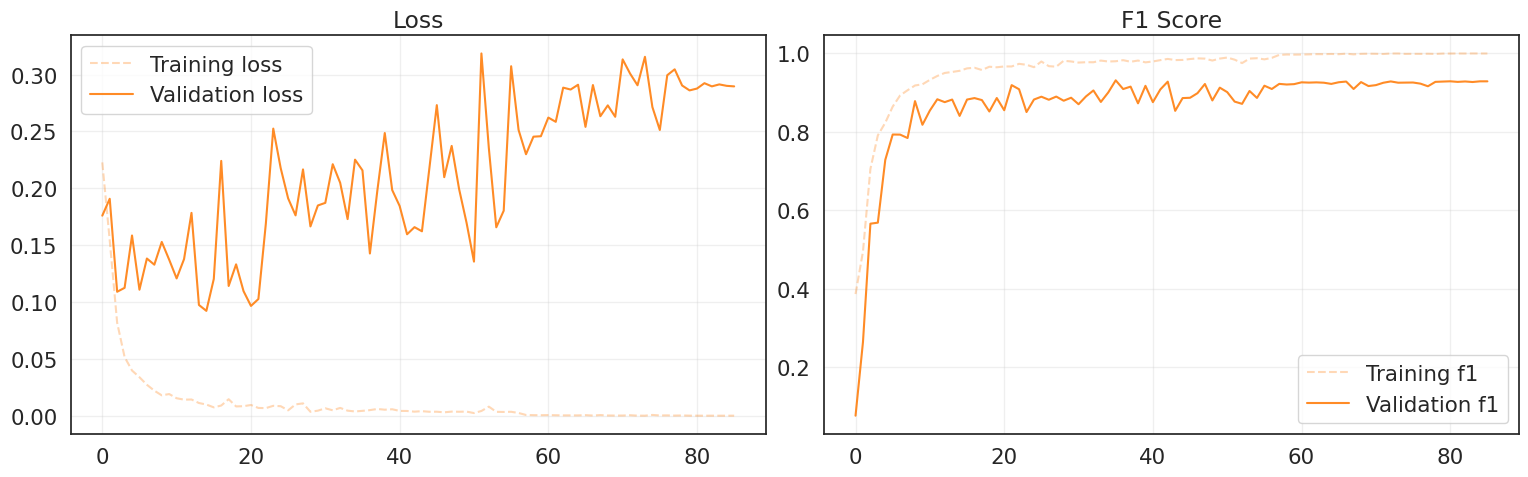

In [59]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.9332
Precision over the validation set: 0.9312
Recall over the validation set: 0.9332
F1 score over the validation set: 0.9315


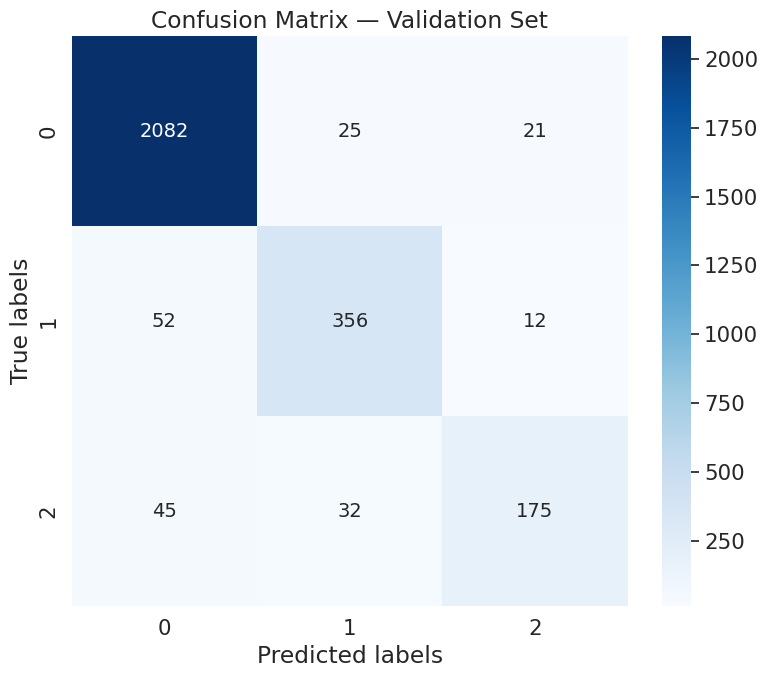

In [60]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device).float()  # Explicitly cast to float32

        # Forward pass: get model predictions
        logits = rnn_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

# some cross validation used for the first 2 models

 To assert the best vavlue for batch size and other parameters since the usage of a GPU was strictly neccessary to train our models, and since we had a daily amount of time, we subdivided our K-valuation of different parameters on subset of those, here is a executed list of some, a commented section is provided to show the actual testing.

 WINDOW_SIZE=[40, 60, 80, 90]

 BATCH_SIZE=[32, 40,80]

 STRIDE=[4,5,10]

HIDDEN_LAYERS=[1,2,3]

HIDDEN_SIZE=[128,256,64]

DROPOUT= [0.4,0.2,0.6]

GAMMA=

## ❌ **Let's do some hyperparameter tuning**

In [61]:
from sklearn.preprocessing import MinMaxScaler

def k_shuffle_split_cross_validation_round_rnn(df, epochs, criterion, device,
                            k, n_val_users, n_test_users, batch_size, hidden_layers, hidden_size, learning_rate, dropout_rate,
                            window_size, stride, rnn_type, bidirectional= True,
                            l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
                            restore_best_weights=True, writer=None, verbose=10, seed=42, experiment_name="",
                            lr_scheduler_patience=20, lr_scheduler_factor=0.1, gamma=1.5):
    """
    Perform K-fold shuffle split cross-validation with user-based splitting for time series data.

    Args:
        df: DataFrame with columns ['sample_index', 'label', 'pain_survey_X', 'joint_XX', 'has_any_disability']
        epochs: Number of training epochs
        criterion: Loss function (will be replaced by FocalLoss within the function)
        device: torch.device for computation
        k: Number of cross-validation splits
        n_val_users: Number of users for validation set
        n_test_users: Number of users for test set
        batch_size: Batch size for training
        hidden_layers: Number of recurrent layers
        hidden_size: Hidden state dimensionality
        learning_rate: Learning rate for optimizer
        dropout_rate: Dropout rate
        window_size: Length of sliding windows
        stride: Step size for sliding windows
        rnn_type: Type of RNN ('RNN', 'LSTM', 'GRU')
        bidirectional: Whether to use bidirectional RNN
        activation_function_type: Type of activation function to use ('None', 'ReLU', 'LeakyReLU', 'ELU')
        l1_lambda: L1 regularization coefficient (if used)
        l2_lambda: L2 regularization coefficient (weight_decay)
        patience: Early stopping patience
        evaluation_metric: Metric to monitor for early stopping
        mode: 'max' or 'min' for evaluation metric
        restore_best_weights: Whether to restore best weights after training
        writer: TensorBoard writer
        verbose: Verbo`sity level
        seed: Random seed
        experiment_name: Name for experiment logging
        lr_scheduler_patience (int): Number of epochs with no improvement after which learning rate will be reduced.
        lr_scheduler_factor (float): Factor by which the learning rate will be reduced.
        gamma (float): Gamma parameter for FocalLoss.

    Returns:
        fold_losses: Dict with validation losses for each split
        fold_metrics: Dict with validation F1 scores for each split
        best_scores: Dict with best F1 score for each split plus mean and std
    """

    # Initialise containers for results across all splits
    fold_losses = {}
    fold_metrics = {}
    best_scores = {}

    # Get model architecture parameters
    # Use global input_shape and num_classes derived from the initial data processing
    in_features = input_shape[-1] # From X_train.shape[1:] computed earlier
    num_classes_model = num_classes # From num_classes computed earlier

    # Initialise model architecture
    model = RecurrentClassifier(
        input_size=in_features,
        hidden_size=hidden_size,
        num_layers=hidden_layers,
        num_classes=num_classes_model, # Use the global num_classes
        dropout_rate=dropout_rate,
        bidirectional=bidirectional,
        rnn_type=rnn_type
    ).to(device)

    # Store initial weights to reset model for each split
    initial_state = copy.deepcopy(model.state_dict())

    # Extract user labels from the original df for stratification
    # Ensure original string labels are used before integer mapping for stratification
    user_labels_full = df[['sample_index', 'label']].drop_duplicates().set_index('sample_index')['label']

    # Iterate through K random splits
    for split_idx in range(k):

        if verbose > 0:
            print(f"Split {split_idx+1}/{k}")

        # Get unique user IDs
        unique_users = df['sample_index'].unique()

        # Create a stratify_labels array corresponding to unique_users
        stratify_labels_for_users = user_labels_full.loc[unique_users].values

        # First split: Separate out test_users (CV test set) from the rest (temp_train_val_users)
        # Use N_TEST_USERS for the test set and stratify
        temp_train_val_users, test_users = train_test_split(
            unique_users,
            test_size=n_test_users,
            stratify=stratify_labels_for_users,
            random_state=seed + split_idx
        )

        # Create stratify_labels for the temp_train_val_users
        stratify_labels_for_temp = user_labels_full.loc[temp_train_val_users].values

        # Second split: Separate temp_train_val_users into train_users and val_users
        # Use N_VAL_USERS for the validation set and stratify
        train_users, val_users = train_test_split(
            temp_train_val_users,
            test_size=n_val_users,
            stratify=stratify_labels_for_temp,
            random_state=seed + split_idx
        )

        # Split the dataset into training, validation, and test sets based on user IDs
        df_train = df[df['sample_index'].isin(train_users)].copy()
        df_val = df[df['sample_index'].isin(val_users)].copy()
        # For cross-validation, df_test_cv needs to be from the train_df to have labels for evaluation
        df_test_cv = df[df['sample_index'].isin(test_users)].copy()

        # Define a mapping of activity names to integer labels - using the global label_mapping
        df_train['label'] = df_train['label'].map(label_mapping)
        df_val['label'] = df_val['label'].map(label_mapping)
        if not df_test_cv.empty:
            df_test_cv['label'] = df_test_cv['label'].map(label_mapping)

        # Define the columns to be normalised (all joint_ columns)
        joint_columns = [col for col in df_train.columns if col.startswith('joint_')]

        # Initialize MinMaxScaler for this fold
        scaler_fold = MinMaxScaler()

        # Fit the scaler on the training data of this fold only
        scaler_fold.fit(df_train[joint_columns])

        # Transform all datasets for this fold
        df_train[joint_columns] = scaler_fold.transform(df_train[joint_columns])
        df_val[joint_columns] = scaler_fold.transform(df_val[joint_columns])
        df_test_cv[joint_columns] = scaler_fold.transform(df_test_cv[joint_columns])


        # Build sequences using the existing build_sequences function
        X_train, y_train_sequences = build_sequences(df_train, window=window_size, stride=stride)
        X_val, y_val = build_sequences(df_val, window=window_size, stride=stride)
        X_test, y_test = build_sequences(df_test_cv, window=window_size, stride=stride)

        # Convert any remaining NaNs or Infs to finite numbers
        X_train = np.nan_to_num(X_train)
        X_val = np.nan_to_num(X_val)
        X_test = np.nan_to_num(X_test)

        if verbose > 0:
            print(f"  Training sequences shape: {X_train.shape}")
            print(f"  Validation sequences shape: {X_val.shape}")
            print(f"  CV Test sequences shape: {X_test.shape}")

        # Create PyTorch datasets, explicitly casting to .float()
        train_ds = TensorDataset(torch.from_numpy(X_train).float(), torch.from_numpy(y_train_sequences))
        val_ds   = TensorDataset(torch.from_numpy(X_val).float(), torch.from_numpy(y_val))
        test_ds  = TensorDataset(torch.from_numpy(X_test).float(), torch.from_numpy(y_test))

        # Calculate class weights for handling imbalanced datasets FOR THIS FOLD
        class_counts_fold = np.bincount(y_train_sequences)
        class_weights_fold = 1.0 / (class_counts_fold + 1e-5)
        class_weights_fold = class_weights_fold / class_weights_fold.sum() * num_classes_model
        class_weights_fold = torch.tensor(class_weights_fold, dtype=torch.float32).to(device)
        if verbose > 0:
            print("  Calculated Fold Class Weights (for FocalLoss alpha):", class_weights_fold)

        # --- Start of weighted sampling logic ---
        weights_vector_fold = []

        # Get user-level information from the current df_train, retaining original string labels
        user_level_info_df_raw_labels = df[['sample_index', 'has_any_disability', 'label']].drop_duplicates(subset=['sample_index']).set_index('sample_index')
        user_level_info_df_raw_labels = user_level_info_df_raw_labels[user_level_info_df_raw_labels.index.isin(df_train['sample_index'].unique())]

        # Calculate weights for 'pirate' and 'no_pirate' users in this fold using ORIGINAL STRING LABELS
        pirate_users_info_fold = user_level_info_df_raw_labels[user_level_info_df_raw_labels['has_any_disability'] == 1]
        pirate_label_counts_fold = pirate_users_info_fold['label'].value_counts()
        total_pirate_users_fold = pirate_label_counts_fold.sum()
        weights_pirate_fold = {
            label: (1.0 / count) * (total_pirate_users_fold / len(pirate_label_counts_fold))
            for label, count in pirate_label_counts_fold.items()
        } if len(pirate_label_counts_fold) > 0 else {} # Handle case where no pirate users in fold
        if sum(weights_pirate_fold.values()) > 0:
            sum_weights_pirate_fold = sum(weights_pirate_fold.values())
            weights_pirate_fold = {label: weight / sum_weights_pirate_fold for label, weight in weights_pirate_fold.items()}


        no_pirate_users_info_fold = user_level_info_df_raw_labels[user_level_info_df_raw_labels['has_any_disability'] == 0]
        no_pirate_label_counts_fold = no_pirate_users_info_fold['label'].value_counts()
        total_no_pirate_users_fold = no_pirate_label_counts_fold.sum()
        weights_no_pirate_fold = {
            label: (1.0 / count) * (total_no_pirate_users_fold / len(no_pirate_label_counts_fold))
            for label, count in no_pirate_label_counts_fold.items()
        } if len(no_pirate_label_counts_fold) > 0 else {} # Handle case where no non-pirate users in fold
        if sum(weights_no_pirate_fold.values()) > 0:
            sum_weights_no_pirate_fold = sum(weights_no_pirate_fold.values())
            weights_no_pirate_fold = {label: weight / sum_weights_no_pirate_fold for label, weight in weights_no_pirate_fold.items()}


        # Reconstruct the mapping from sequence index in train_ds to its original sample_index (user_id)
        original_sample_indices_for_train_sequences_fold = []
        for user_id in df_train['sample_index'].unique():
            user_data_len = len(df_train[df_train['sample_index'] == user_id])
            padding_len = (window_size - (user_data_len % window_size)) % window_size
            total_len_after_padding = user_data_len + padding_len

            idx = 0
            while idx + window_size <= total_len_after_padding:
                original_sample_indices_for_train_sequences_fold.append(user_id)
                idx += stride

        if len(original_sample_indices_for_train_sequences_fold) != len(train_ds):
            raise ValueError(
                f"Mismatch in number of sequences for weight calculation and actual train_ds length for split {split_idx}.\n"
                f"Expected {len(train_ds)} sequences, but got {len(original_sample_indices_for_train_sequences_fold)}."
                "This indicates an inconsistency in how sequences are generated or accounted for."
            )

        for sequence_original_sample_index in original_sample_indices_for_train_sequences_fold:
            has_disability = user_level_info_df_raw_labels.loc[sequence_original_sample_index, 'has_any_disability']
            # Retrieve the original string label directly
            original_string_label = user_level_info_df_raw_labels.loc[sequence_original_sample_index, 'label']

            if has_disability:
                weight = weights_pirate_fold.get(original_string_label, 1.0)
            else:
                weight = weights_no_pirate_fold.get(original_string_label, 1.0)

            weights_vector_fold.append(weight)

        weights_vector_fold = torch.tensor(weights_vector_fold, dtype=torch.float32)

        weighted_sampler_fold = WeightedRandomSampler(weights=weights_vector_fold, num_samples=len(train_ds), replacement=True)

        # --- End of weighted sampling logic ---

        # Create data loaders, passing the weighted_sampler_fold to train_loader
        # shuffle=False when using a sampler
        train_loader = make_loader(train_ds, batch_size=batch_size, shuffle=False, drop_last=False, sampler=weighted_sampler_fold)
        val_loader   = make_loader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False)
        test_loader  = make_loader(test_ds, batch_size=batch_size, shuffle=False, drop_last=False)

        # Reset model to initial weights for fair comparison across splits
        model.load_state_dict(initial_state)

        # Define optimizer with L2 regularization
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=l2_lambda)

        # Enable mixed precision training for GPU acceleration
        split_scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

        # Create directory for model checkpoints
        os.makedirs(f"models/{experiment_name}", exist_ok=True)

        # Re-initialize criterion with fold-specific class weights and FocalLoss
        criterion_per_fold = FocalLoss(alpha=class_weights_fold, gamma=gamma, reduction='mean') # Use gamma parameter here

        # Initialize ReduceLROnPlateau scheduler for this fold
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode=mode,
            factor=lr_scheduler_factor,
            patience=lr_scheduler_patience,
            min_lr=1e-7 # Define a minimum learning rate
        )

        # Train model on current split
        model, training_history = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion_per_fold, # Use fold-specific criterion
            optimizer=optimizer,
            scaler=split_scaler,
            device=device,
            writer=writer,
            patience=patience,
            verbose=verbose,
            l1_lambda=l1_lambda,
            evaluation_metric=evaluation_metric,
            mode=mode,
            restore_best_weights=restore_best_weights,
            experiment_name=experiment_name+"/split_"+str(split_idx),
            scheduler=scheduler # Pass the scheduler to the fit function
        )

        # Store results for this split
        fold_losses[f"split_{split_idx}"] = training_history['val_loss']
        fold_metrics[f"split_{split_idx}"] = training_history['val_f1']
        best_scores[f"split_{split_idx}"] = max(training_history['val_f1'])

    # Compute mean and standard deviation of best scores across splits
    best_scores["mean"] = np.mean([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])
    best_scores["std"] = np.std([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])

    if verbose > 0:
        print(f"Best score: {best_scores['mean']:.4f}\u00B1{best_scores['std']:.4f}")

    return fold_losses, fold_metrics, best_scores


def grid_search_cv_rnn(df, param_grid, fixed_params, cv_params, verbose=True):
    """
    Execute grid search with K-shuffle-split cross-validation for RNN models on time series data.

    Args:
        df: DataFrame with columns ['user_id', 'activity', 'x_axis', 'y_axis', 'z_axis', 'id']
        param_grid: Dict of parameters to test, e.g. {'batch_size': [16, 32], 'rnn_type': ['LSTM', 'GRU']}
        fixed_params: Dict of fixed hyperparameters (hidden_size, learning_rate, window_size, stride, etc.)
        cv_params: Dict of CV settings (epochs, k, patience, criterion, scaler, device, etc.)
        verbose: Print progress for each configuration

    Returns:
        results: Dict with scores for each configuration
        best_config: Dict with best hyperparameter combination
        best_score: Best mean F1 score achieved
    """
    # Generate all parameter combinations
    param_names = list(param_grid.keys())
    param_values = list(param_grid.values())
    combinations = list(product(*param_values))

    results = {}
    best_score = -np.inf
    best_config = None

    total = len(combinations)

    for idx, combo in enumerate(combinations, 1):
        # Create current configuration dict
        current_config = dict(zip(param_names, combo))
        config_str = "_".join([f"{k}_{v}" for k, v in current_config.items()])

        if verbose:
            print(f"\nConfiguration {idx}/{total}:")
            for param, value in current_config.items():
                print(f"  {param}: {value}")

        # Merge current config with fixed parameters
        run_params = {**fixed_params, **current_config}

        # Execute cross-validation
        _, _, fold_scores = k_shuffle_split_cross_validation_round_rnn(
            df=df,
            experiment_name=config_str,
            **run_params,
            **cv_params
        )

        # Store results
        results[config_str] = fold_scores

        # Track best configuration
        if fold_scores["mean"] > best_score:
            best_score = fold_scores["mean"]
            best_config = current_config.copy()
            if verbose:
                print("  NEW BEST SCORE!")

        if verbose:
            print(f"  F1 Score: {fold_scores['mean']:.4f}\u00B1{fold_scores['std']:.4f}")

    return results, best_config, best_score


def plot_top_configurations_rnn(results, k_splits, top_n=5, figsize=(14, 7)):
    """
    Visualise top N RNN configurations with boxplots of F1 scores across CV splits.

    Args:
        results: Dict of results from grid_search_cv_rnn
        k_splits: Number of CV splits used
        top_n: Number of top configurations to display
        figsize: Figure size tuple
    """
    # Sort by mean score
    config_scores = {name: data['mean'] for name, data in results.items()}
    sorted_configs = sorted(config_scores.items(), key=lambda x: x[1], reverse=True)

    # Select top N
    top_configs = sorted_configs[:min(top_n, len(sorted_configs))]

    # Prepare boxplot data
    boxplot_data = []
    labels = []

    # Define a dictionary for replacements, ordered to handle prefixes correctly
    replacements = {
        'batch_size_': 'BS=',
        'learning_rate_': '\nLR=',
        'hidden_layers_': '\nHL=',
        'hidden_size_': '\nHS=',
        'dropout_rate_': '\nDR=',
        'window_size_': '\nWS=',
        'stride_': '\nSTR=',
        'rnn_type_': '\nRNN=',
        'bidirectional_': '\nBIDIR=',
        'l1_lambda_': '\nL1=',
        'l2_lambda_': '\nL2=',
        'activation_function_type_': '\nACT=' # Updated key
    }

    # Replacements for separators
    separator_replacements = {
        '_learning_rate_': '\nLR=',
        '_hidden_layers_': '\nHL=',
        '_hidden_size_': '\nHS=',
        '_dropout_rate_': '\nDR=',
        '_window_size_': '\nWS=',
        '_stride_': '\nSTR=',
        '_rnn_type_': '\nRNN=',
        '_bidirectional_': '\nBIDIR=',
        '_l1_lambda_': '\nL1=',
        '_l2_lambda_': '\nL2=',
        '_activation_function_type_': '\nACT=', # Updated key
        '_': ''
    }

    for config_name, mean_score in top_configs:
        # Extract best score from each split (auto-detect number of splits)
        split_scores = []
        for i in range(k_splits):
            if f'split_{i}' in results[config_name]:
                split_scores.append(results[config_name][f'split_{i}']) # Access the first element if it's a list
        boxplot_data.append(split_scores)

        # Verify we have the expected number of splits
        if len(split_scores) != k_splits:
            print(f"Warning: Config {config_name} has {len(split_scores)} splits, expected {k_splits}")

        # Create readable label using the replacements dictionary
        readable_label = config_name
        for old, new in replacements.items():
            readable_label = readable_label.replace(old, new)

        # Apply separator replacements
        for old, new in separator_replacements.items():
             readable_label = readable_label.replace(old, new)

        labels.append(f"{readable_label}\n(\u03BC={mean_score:.3f})")

    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    bp = ax.boxplot(boxplot_data, labels=labels, patch_artist=True,
                    showmeans=True, meanline=True)

    # Styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)

    # Highlight best configuration
    if labels:
        ax.get_xticklabels()[0].set_fontweight('bold')

    ax.set_ylabel('F1 Score')
    ax.set_xlabel('Configuration')
    ax.set_title(f'Top {len(top_configs)} RNN Configurations - F1 Score Distribution Across {k_splits} Splits')
    ax.grid(alpha=0.3, axis='y')

    plt.xticks(rotation=0, ha='center')
    plt.tight_layout()
    plt.show()

In [71]:

K=2 # Setting K to 2 to have enough splits for mean/std. It was 1 previously.
# Define parameters to search
param_grid = {
    'window_size': [40],
    'stride': [4, 8],
    'batch_size': [128],
    'dropout_rate': [0.2],
    'hidden_layers': [2],
    'hidden_size': [256],
    'l1_lambda': [0.000],
    'l2_lambda': [0.000],
    'gamma': [ 2.0],
}

# Fixed hyperparameters (not being tuned)
fixed_params = {
    'rnn_type': 'LSTM',
    'learning_rate': 1e-3,
    'bidirectional': True
}

# Cross-validation settings
cv_params = {
    'epochs': EPOCHS,
    'criterion': CRITERION,
    'device': device,
    'k': K,
    'n_val_users': 60,
    'n_test_users': 60,
    'patience': PATIENCE,
    'verbose': 0,
    'seed': SEED,
    'lr_scheduler_patience': 20,
    'lr_scheduler_factor': 0.2,
}

# Execute search
results, best_config, best_score = grid_search_cv_rnn(
    df=df,
    param_grid=param_grid,
    fixed_params=fixed_params,
    cv_params=cv_params
)



Configuration 1/2:
  window_size: 40
  stride: 4
  batch_size: 128
  dropout_rate: 0.2
  hidden_layers: 2
  hidden_size: 256
  l1_lambda: 0.0
  l2_lambda: 0.0
  gamma: 2.0
Training 500 epochs...
Early stopping triggered after 123 epochs.
Best model restored from epoch 73 with val_f1 0.9715
Training 500 epochs...
Early stopping triggered after 109 epochs.
Best model restored from epoch 59 with val_f1 0.9260
  NEW BEST SCORE!
  F1 Score: 0.9488±0.0227

Configuration 2/2:
  window_size: 40
  stride: 8
  batch_size: 128
  dropout_rate: 0.2
  hidden_layers: 2
  hidden_size: 256
  l1_lambda: 0.0
  l2_lambda: 0.0
  gamma: 2.0
Training 500 epochs...
Early stopping triggered after 150 epochs.
Best model restored from epoch 100 with val_f1 0.9642
Training 500 epochs...
Early stopping triggered after 142 epochs.
Best model restored from epoch 92 with val_f1 0.9102
  F1 Score: 0.9372±0.0270


# what if we feed the RNN with the data processed by a CNN?





## Class definition and model declaration

In [65]:
class CNNFeatureExtractor(nn.Module):
    def __init__(
        self,
        input_size, # This will be num_features
        sequence_length, # This will be WINDOW_SIZE
        num_filters=128,
        kernel_size=5,
        stride=1,
        padding=2, # To maintain sequence length if stride=1
        num_cnn_layers=2,
        pool_size=2
    ):
        super().__init__()

        self.conv_layers = nn.ModuleList()
        # First layer converts input_size (features) to num_filters
        # Conv1d expects (batch_size, in_channels, sequence_length)
        self.conv_layers.append(nn.Conv1d(input_size, num_filters, kernel_size=kernel_size, stride=stride, padding=padding))
        self.conv_layers.append(nn.ReLU())
        self.conv_layers.append(nn.MaxPool1d(kernel_size=pool_size))

        # Remaining layers keep num_filters as in_channels and out_channels
        for _ in range(num_cnn_layers - 1):
            self.conv_layers.append(nn.Conv1d(num_filters, num_filters, kernel_size=kernel_size, stride=stride, padding=padding))
            self.conv_layers.append(nn.ReLU())
            self.conv_layers.append(nn.MaxPool1d(kernel_size=pool_size))

        # Calculate output sequence length after convolutional and pooling layers
        current_sequence_length = sequence_length
        for _ in range(num_cnn_layers):
            # After Conv1d (with stride from init params, dilation=1)
            current_sequence_length = (current_sequence_length + 2 * padding - (kernel_size - 1) - 1) // stride + 1

            # After MaxPool1d (with kernel_size=pool_size and default stride=pool_size)
            current_sequence_length = (current_sequence_length - pool_size) // pool_size + 1

            if current_sequence_length < 1:
                raise ValueError("Sequence length became too small after convolution/pooling. Consider adjusting num_cnn_layers, window_size, kernel_size, padding, or pool_size.")

        # This `output_sequence_length` is the length of the sequence that the CNN outputs
        self.output_sequence_length = current_sequence_length
        # The number of features per timestep in the output sequence is `num_filters`
        self.output_feature_dim = num_filters

    def forward(self, x):
        # x shape: (batch_size, original_sequence_length, input_size)
        # Permute to (batch_size, in_channels, sequence_length) for Conv1d
        x = x.permute(0, 2, 1)
        for layer in self.conv_layers:
            x = layer(x)
        # Permute back to (batch_size, new_sequence_length, output_feature_dim) for RNN
        return x.permute(0, 2, 1)


class CNNClassifier(nn.Module):
    def __init__(
        self,
        input_size,
        sequence_length,
        num_classes,
        num_filters=128,
        kernel_size=5,
        stride=1,
        padding=2,
        num_cnn_layers=2,
        pool_size=2,
        dropout_rate=0.3
    ):
        super().__init__()
        # For standalone CNNClassifier, `CNNFeatureExtractor` should flatten its output before the linear layer.
        # To reuse CNNFeatureExtractor, we'll make a separate flattening step here.

        self.feature_extractor_seq = CNNFeatureExtractor(
            input_size=input_size,
            sequence_length=sequence_length,
            num_filters=num_filters,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            num_cnn_layers=num_cnn_layers,
            pool_size=pool_size
        )
        # Calculate the flattened size
        flattened_feature_size = self.feature_extractor_seq.output_sequence_length * self.feature_extractor_seq.output_feature_dim

        self.dropout = nn.Dropout(dropout_rate)
        self.classifier = nn.Linear(flattened_feature_size, num_classes)

    def forward(self, x):
        features_seq = self.feature_extractor_seq(x)
        features_flat = features_seq.flatten(1) # Flatten the sequence for the linear classifier
        features = self.dropout(features_flat)
        logits = self.classifier(features)
        return logits

In [66]:
class CNN_RNN_CombinedClassifier(nn.Module):
    def __init__(
        self,
        input_size,         # This will be input_shape[-1] (num_features)
        sequence_length,    # This will be WINDOW_SIZE
        num_classes,
        # CNN parameters
        cnn_num_filters=128,
        cnn_kernel_size=5,
        cnn_stride=1,
        cnn_padding=2,
        cnn_num_cnn_layers=2,
        cnn_pool_size=2,
        # RNN parameters
        rnn_hidden_size=128,
        rnn_num_layers=1,
        rnn_type='LSTM',
        rnn_bidirectional=True,
        # General regularization
        dropout_rate=0.3
    ):
        super().__init__()

        # Instantiate CNNFeatureExtractor
        # This CNNFeatureExtractor will now produce a sequence of features for the RNN
        self.cnn_feature_extractor = CNNFeatureExtractor(
            input_size=input_size,
            sequence_length=sequence_length,
            num_filters=cnn_num_filters,
            kernel_size=cnn_kernel_size,
            stride=cnn_stride,
            padding=cnn_padding,
            num_cnn_layers=cnn_num_cnn_layers,
            pool_size=cnn_pool_size
        )

        # The output feature size from the CNN feature extractor, which becomes the input_size for the RNN
        # This is `cnn_num_filters` because the CNN outputs a sequence where each timestep has `cnn_num_filters` features.
        cnn_output_feature_dim = cnn_num_filters

        # Instantiate RecurrentClassifier to process the CNN's output sequence
        self.rnn_classifier = RecurrentClassifier(
            input_size=cnn_output_feature_dim, # Input to RNN is the feature dimension from CNN output
            hidden_size=rnn_hidden_size,
            num_layers=rnn_num_layers,
            num_classes=num_classes, # Pass the num_classes argument
            rnn_type=rnn_type,
            bidirectional=rnn_bidirectional,
            dropout_rate=dropout_rate
        )


    def forward(self, x):
        # x shape: (batch_size, original_sequence_length, input_size)

        # Pass input through CNN feature extractor to get a sequential output
        # cnn_output_sequence shape: (batch_size, new_sequence_length, cnn_num_filters)
        cnn_output_sequence = self.cnn_feature_extractor(x)

        # Pass the CNN's sequential output to the RNN classifier
        logits = self.rnn_classifier(cnn_output_sequence)

        return logits

In [67]:
def model_summary(model, input_tensor_shape):
    """
    Prints a summary of the model similar to torchinfo.summary.
    Args:
        model (nn.Module): The PyTorch model to summarize.
        input_tensor_shape (tuple): The shape of the dummy input tensor (e.g., (batch_size, seq_len, features)).
    """
    print(model)
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\nTotal params: {total_params:,}")
    print(f"Trainable params: {trainable_params:,}")
    print(f"Non-trainable params: {total_params - trainable_params:,}")

# Change MODEL_ARCHITECTURE to use the new attention model
# Set MODEL_ARCHITECTURE = 'CNN_RNN_ATTENTION' to try the new model
# MODEL_ARCHITECTURE = 'CNN_RNN_ATTENTION'

if MODEL_ARCHITECTURE == 'CNN':
    model = CNNClassifier(
        input_size=input_shape[-1],
        sequence_length=WINDOW_SIZE,
        num_classes=num_classes,
        dropout_rate=DROPOUT_RATE,
        num_filters=HIDDEN_SIZE,
        num_cnn_layers=HIDDEN_LAYERS,
        kernel_size=5,
        pool_size=2
    ).to(device)
    print("CNNClassifier model created.")
elif MODEL_ARCHITECTURE == 'RNN':
    model = RecurrentClassifier(
        input_size=input_shape[-1],
        hidden_size=HIDDEN_SIZE,
        num_layers=HIDDEN_LAYERS,
        num_classes=num_classes,
        rnn_type=RNN_TYPE,
        bidirectional=RNN_BIDIRECTIONAL,
        dropout_rate=DROPOUT_RATE
    ).to(device)
    print("RecurrentClassifier model created.")
elif MODEL_ARCHITECTURE == 'CNN_RNN':
    model = CNN_RNN_CombinedClassifier(
        input_size=input_shape[-1],
        sequence_length=WINDOW_SIZE,
        num_classes=num_classes,
        cnn_num_filters=CNN_RNN_CNN_FILTERS,
        cnn_kernel_size=CNN_RNN_CNN_KERNEL_SIZE,
        cnn_num_cnn_layers=CNN_RNN_CNN_LAYERS,
        cnn_pool_size=CNN_RNN_CNN_POOL_SIZE,
        rnn_hidden_size=CNN_RNN_RNN_HIDDEN_SIZE,
        rnn_num_layers=CNN_RNN_RNN_LAYERS,
        rnn_type=RNN_TYPE,
        rnn_bidirectional=RNN_BIDIRECTIONAL,
        dropout_rate=DROPOUT_RATE
    ).to(device)
    print("CNN_RNN_CombinedClassifier model created.")
else:
    raise ValueError("Invalid MODEL_ARCHITECTURE specified.")

# Display model summary
model_summary(model, (BATCH_SIZE, input_shape[0], input_shape[1]))

# Set up TensorBoard logging and save model architecture
experiment_name = f"{MODEL_ARCHITECTURE}_{RNN_TYPE}_{RNN_BIDIRECTIONAL}_ws{WINDOW_SIZE}_bs{BATCH_SIZE}_stride{STRIDE}_lr{LEARNING_RATE}_gamma{GAMMA}"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_shape[0], input_shape[1]).to(device)
writer.add_graph(model, x)

# Define optimizer with L2 regularization
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Initialize ReduceLROnPlateau scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.1,
    patience=20,
    min_lr=1e-6
)

CNN_RNN_CombinedClassifier model created.
CNN_RNN_CombinedClassifier(
  (cnn_feature_extractor): CNNFeatureExtractor(
    (conv_layers): ModuleList(
      (0): Conv1d(36, 128, kernel_size=(7,), stride=(1,), padding=(2,))
      (1): ReLU()
      (2): MaxPool1d(kernel_size=1, stride=1, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (rnn_classifier): RecurrentClassifier(
    (rnn): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
    (classifier): Linear(in_features=256, out_features=3, bias=True)
  )
)

Total params: 692,611
Trainable params: 692,611
Non-trainable params: 0


## 📑 **Train the other "mind"**

In [68]:
%%time
# Train model and track training history
model, training_history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=CRITERION,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=10,
    l1_lambda=L1_LAMBDA,
    l2_lambda=L2_LAMBDA,
    #expreiment_name with all parameters
    experiment_name = f"{MODEL_ARCHITECTURE}_{RNN_BIDIRECTIONAL}_ws{WINDOW_SIZE}_bs{BATCH_SIZE}_stride{STRIDE}_lr{LEARNING_RATE}_gamma{GAMMA}",
    patience=PATIENCE,
    scheduler=scheduler
    )

# Update best model if current performance is superior
if training_history['val_f1'][-1] > best_performance:
    best_model = model
    best_performance = training_history['val_f1'][-1]

Training 500 epochs...
Epoch   1/500 | Train: Loss=0.2140, F1 Score=0.4300 | Val: Loss=0.1607, F1 Score=0.3504 | LR=0.001000
Epoch  10/500 | Train: Loss=0.0198, F1 Score=0.9168 | Val: Loss=0.1955, F1 Score=0.7971 | LR=0.001000
Epoch  20/500 | Train: Loss=0.0098, F1 Score=0.9564 | Val: Loss=0.1791, F1 Score=0.8834 | LR=0.001000
Epoch  30/500 | Train: Loss=0.0082, F1 Score=0.9630 | Val: Loss=0.1947, F1 Score=0.8825 | LR=0.001000
Epoch  40/500 | Train: Loss=0.0064, F1 Score=0.9772 | Val: Loss=0.2292, F1 Score=0.9019 | LR=0.001000
Epoch  50/500 | Train: Loss=0.0027, F1 Score=0.9863 | Val: Loss=0.2863, F1 Score=0.9161 | LR=0.001000
Epoch  60/500 | Train: Loss=0.0006, F1 Score=0.9964 | Val: Loss=0.2778, F1 Score=0.9225 | LR=0.000100
Epoch  70/500 | Train: Loss=0.0004, F1 Score=0.9983 | Val: Loss=0.3486, F1 Score=0.9228 | LR=0.000100
Epoch  80/500 | Train: Loss=0.0004, F1 Score=0.9982 | Val: Loss=0.3591, F1 Score=0.9301 | LR=0.000100
Epoch  90/500 | Train: Loss=0.0002, F1 Score=0.9991 | Val: 

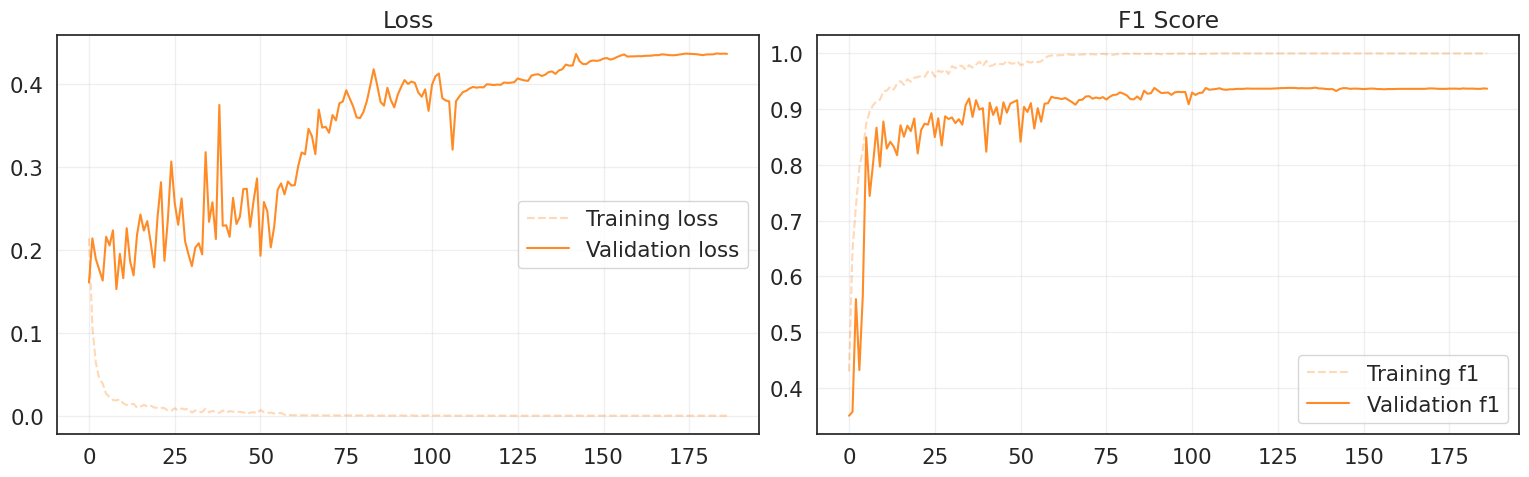

In [69]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.9407
Precision over the validation set: 0.9390
Recall over the validation set: 0.9407
F1 score over the validation set: 0.9383


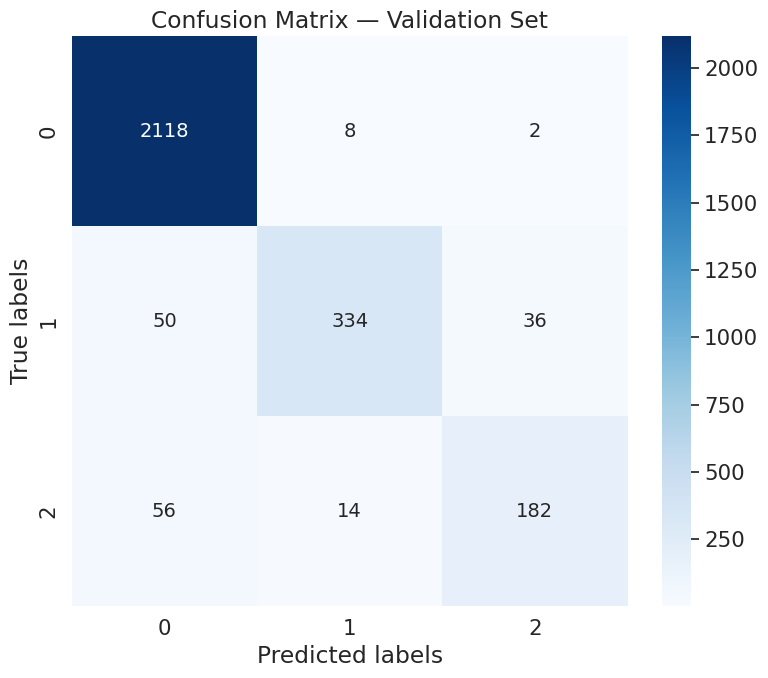

In [70]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device).float()  # Explicitly cast to float32

        # Forward pass: get model predictions
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()